# Emise českých zařízení v EU ETS1: kolik poklesu jde na vrub zavírání a kolik snižování v provozech

**Cíl notebooku:** projít celý postup od surového souboru z Union Registry až po grafy tak, abyste každý krok mohla
zkontrolovat, ověřit a případně změnit. U každého kroku je psáno **co se dělá, proč a jak to ověřit**.

**Jak s notebookem pracovat**
1. Nahoře v první buňce nastavte cestu k souboru `verified_emissions_2025_en.xlsx` (proměnná `XLSX`).
2. Spouštějte buňky shora dolů (`Shift+Enter`). Každá sekce stojí na předchozích.
3. U každé sekce je odstavec **„Proč“** (odůvodnění) a **„Jak to ověřit“** (co si můžete zkontrolovat sama).
4. Na konci jsou cvičení, jak postup upravit a naučit se z něj.

**Obsah**
1. Načtení dat a ověření, že popis sloupců sedí
2. Filtr: jen Česko a jen stacionární zařízení
3. Příprava: matice emisí a přídělů (NaN × 0 × „Excluded“)
4. Celkové emise ČR po letech a volba výchozího roku
5. Rozklad meziroční změny: princip a první pokus (přísné kritérium přes příděl)
6. Co jsou „nejasné“ případy a Ledvice 4 (sečtení s Ledvicemi)
7. Finální rozklad, kumulativní pohled, kontrolní asserty
8. Okrajové případy (mezery v řadě, „Excluded“, rok 2025, změny rozsahu)
9. Citlivostní analýza
10. Největší zavřená zařízení a společnosti
11. Nová zařízení
12. Grafy
13. Shrnutí, co je nejisté, cvičení

## Hlavní závěry (abyste věděla, kam se jde)

* Emise českých stacionárních zařízení v ETS1 klesly z **67,7 Mt (2013)** na **40,0 Mt (2025)**, tedy o **41 %** (−27,7 Mt).
* Z poklesu připadá zhruba **91 % na pokračující zařízení** (méně výroby, odstavování bloků, přechod paliv),
  **9 % na zavřená zařízení** a **nová zařízení pokles zmírnila o 0,3 %**.
* Nových zařízení vzniklo od 2014 jen 19 a v roce 2025 emitují dohromady jen ~0,1 Mt.
* **Ledvice 4 a „ČEZ – Elektrárna Ledvice“ se berou jako jedno zařízení (společnost)**, emise i příděly se sečtou (sekce 6).
  Bez toho by Ledvice 4 vypadaly jako největší zavření a Ledvice jako nárůst emisí; zavírání by pak vycházelo na ≈ 17 % místo 9 %.

In [1]:
import os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["font.family"] = "DejaVu Sans"

# >>> NASTAVTE cestu k souboru (nebo proměnnou prostředí ETS_XLSX) <<<
XLSX = os.environ.get("ETS_XLSX", r"G:\My Drive\EU_ETS1\verified_emissions_2025_en.xlsx")

YEARS = list(range(2013, 2026))   # roky, které analyzujeme (data jsou srovnatelná od 2013)
BASE = YEARS[0]                   # výchozí rok pro kumulativní změnu
EXPORT = False                    # True = grafy se uloží do složky vystupy_notebook (PNG 300 dpi + SVG)
OUT = Path("vystupy_notebook")

## 1. Načtení dat a ověření, že popis sloupců sedí

**Proč:** zadání popisovalo tabulku jako „long“ (řádek = zařízení × rok, sloupec `year`). Než cokoli spočítáme, musíme
zjistit, jak data vypadají doopravdy. Špatný předpoklad o struktuře by zkreslil všechno, co následuje.

**Co se dělá:** načteme list `data`. V Excelu je hlavička až na 3. řádku, proto `header=2`.

In [2]:
xl = pd.ExcelFile(XLSX)
print("Listy v souboru:", xl.sheet_names)

raw = pd.read_excel(xl, sheet_name="data", header=2)   # hlavička je na 3. řádku listu
print("Rozměr tabulky (řádky x sloupce):", raw.shape)
raw.iloc[:4, :8]

Listy v souboru: ['Read Me', 'data', 'activity codes', 'CH adm. Aviation Operators']


Rozměr tabulky (řádky x sloupce): (18993, 85)


,REGISTRY_CODE,IDENTIFIER_IN_REG,INSTALLATION_NAME,INSTALLATION_IDENTIFIER,PERMIT_IDENTIFIER,MAIN_ACTIVITY_TYPE_CODE,ALLOCATION_2025,ALLOCATION_RESERVE_2025
0,AT,Michael Strasser GmbH & Co. KG,13030,201505,BMLFUW‐UW.1.3.2/0121‐V/4/2011,10,NaN,NaN
1,AT,Georgetown Management LLC,15451,201836,BMLFUW-UW.1.3.2/0121-V/4/2010,10,NaN,NaN
2,AT,PSC Ukraine International Airlines,19210,201564,BMLFUW-UW.1.3.2/0001-I/4/2015,10,NaN,NaN
3,AT,Glock Gesellschaft m.b.H.,194,200108,BMFLUW-UW.1.3.2/0084-V/4/2010,10,NaN,NaN


Listy `Read Me` a `activity codes` obsahují **dokumentaci a číselník**. Přečteme si je, protože z nich plyne význam
prázdných buněk, hodnoty `Excluded` a kódů činností.

In [3]:
readme = pd.read_excel(xl, sheet_name="Read Me", header=None)
for text in readme.to_numpy().ravel():
    if isinstance(text, str) and len(text) > 3:
        print("•", text[:420])

• Date of Extraction
• INFO
• n/a = blank (No allocation has been made / No Emissions have been Verified)
•   0 = 0 units have been Allocated and/or the amount of verified emission reported is zero. 
• NOTES
• Excluded = A stationary installation or an aircraft operator is out of scope of the EU ETS (and CH ETS for aircraft operators) for the specific year
• This file contains historical data since 2008. As of 2013 data is not directly comparable to data of 2012 and before given the extended scope of the EU ETS in phase III.
• Regarding free allocation to stationary installations, as of 2013, this file distinguishes between the allocation  of allowances free of charge to existing installations (Article 10a(1)), the allocation  of allowances free of charge for modernisation of electricity generation (Article 10c) and the allocation  of allowances free of charge from the new entrant reserve (Article 10a(7))
• This file does not contain emissions data for stationary installations and airc

### Z dokumentace plyne (důležité pro celý zbytek)
* **prázdná buňka** = nebyl přidělen příděl / nebyly ověřeny emise; **0** = skutečná nula,
* **`Excluded`** = zařízení je pro daný rok **mimo rozsah ETS** (to není zavření!),
* data jsou **srovnatelná až od 2013** (rozšíření rozsahu ve fázi III), zaniklá zařízení před 2013 v souboru nejsou,
* `CH_*` sloupce patří švýcarskému propojení (jen letectví).

Teď zkontrolujeme, jak vypadají sloupce.

In [4]:
prefixy = sorted({re.sub(r"_?\d{4}$", "", c) for c in raw.columns})
print("Názvy sloupců bez roku:\n ", prefixy)
print()
print("Sloupec 'year' existuje?  ", "year" in raw.columns)
print("Sloupec 'pomer' existuje? ", "pomer" in raw.columns)
print("Sloupce pro rok 2025:     ", [c for c in raw.columns if "2025" in c])

Názvy sloupců bez roku:
  ['ACCOUNT_CLOSURE', 'ACCOUNT_TYPE', 'ALLOCATION', 'ALLOCATION_BYICELAND', 'ALLOCATION_FEETS', 'ALLOCATION_RESERVE', 'ALLOCATION_TRANSITIONAL', 'CH_ALLOCATION', 'CH_VERIFIED_EMISSIONS', 'IDENTIFIER_IN_REG', 'IMO_NUMBER', 'INSTALLATION_IDENTIFIER', 'INSTALLATION_NAME', 'MAIN_ACTIVITY_TYPE_CODE', 'PERMIT_IDENTIFIER', 'REGISTRY_CODE', 'VERIFIED_EMISSIONS']

Sloupec 'year' existuje?   False
Sloupec 'pomer' existuje?  False
Sloupce pro rok 2025:      ['ALLOCATION_2025', 'ALLOCATION_RESERVE_2025', 'ALLOCATION_TRANSITIONAL_2025', 'ALLOCATION_FEETS_2025', 'ALLOCATION_BYICELAND_2025', 'CH_ALLOCATION_2025', 'VERIFIED_EMISSIONS_2025', 'CH_VERIFIED_EMISSIONS_2025']


### Zjištění č. 1: soubor je „wide“, ne „long“

Místo sloupců `year` a `VERIFIED_EMISSIONS` jsou tu sloupce `VERIFIED_EMISSIONS_2013 … _2025`, `ALLOCATION_2013 … _2025` atd.
Sloupec `pomer` v souboru není (byl to váš vlastní dopočet v jiné verzi tabulky), a proto ho **nepoužíváme**.

**Důsledek:** data buď přetavíme do „long“ (`melt`), nebo budeme pracovat s maticemi *zařízení × rok*.
Pro náš rozklad jsou praktičtější **matice** (rozdíl dvou sousedních sloupců je okamžitě rozdíl let), long ukážeme
jen pro ilustraci v sekci 3.

### Co zadání tvrdilo a co jsme zjistili

| Tvrzení v zadání | Realita v souboru |
|---|---|
| DataFrame je „long“, sloupec `year` | **wide**, sloupce s příponou `_rok` |
| sloupec `pomer` | v souboru **není** |
| `IDENTIFIER_IN_REG` / `INSTALLATION_IDENTIFIER` je klíč zařízení | `IDENTIFIER_IN_REG` je **název držitele**, klíč je `INSTALLATION_IDENTIFIER` (ověříme níže) |
| `ALLOCATION_FEETS`, `_BYICELAND` existují | existují **jen pro 2025**, u ČR jsou nulové (ověříme níže) |
| `VERIFIED_EMISSIONS` je číslo | někde je text **`Excluded`** |

## 2. Filtr: jen Česko a jen stacionární zařízení

### 2a) Stát
`REGISTRY_CODE == "CZ"`. Nejdřív se podíváme na unikátní hodnoty, abychom viděli, že kód Česka je opravdu `CZ`.

In [5]:
print(raw.REGISTRY_CODE.value_counts().head(15).to_string())
cz = raw[raw.REGISTRY_CODE == "CZ"].copy()
print("\nŘádků pro CZ (stacionární + letadla):", len(cz))

REGISTRY_CODE
DE    3154
ES    2048
FR    1759
IT    1715
GB    1526
NL     990
GR     980
SE     950
PL     900
FI     701
BE     585
DK     439
CZ     374
NO     368
RO     331

Řádků pro CZ (stacionární + letadla): 374


### 2b) Který sloupec je klíč zařízení?

**Proč:** klíč musí být **unikátní** (jedno zařízení = jeden řádek) a **stabilní** (stejný napříč roky). Ve wide formátu
stabilita roste automaticky, ale unikátnost musíme ověřit.

In [6]:
for c in ["IDENTIFIER_IN_REG", "INSTALLATION_IDENTIFIER", "PERMIT_IDENTIFIER", "INSTALLATION_NAME"]:
    print(f"{c:26s} unikátních: {cz[c].nunique():4d} z {len(cz)} | chybějících: {cz[c].isna().sum()}")

print("\nHodnoty IDENTIFIER_IN_REG, které se opakují (dva řádky = stejná firma, jiné zařízení):")
cz[cz.IDENTIFIER_IN_REG.duplicated(keep=False)][["IDENTIFIER_IN_REG", "INSTALLATION_NAME", "INSTALLATION_IDENTIFIER"]]

IDENTIFIER_IN_REG          unikátních:  372 z 374 | chybějících: 0
INSTALLATION_IDENTIFIER    unikátních:  374 z 374 | chybějících: 0
PERMIT_IDENTIFIER          unikátních:  374 z 374 | chybějících: 0
INSTALLATION_NAME          unikátních:  373 z 374 | chybějících: 0

Hodnoty IDENTIFIER_IN_REG, které se opakují (dva řádky = stejná firma, jiné zařízení):


,IDENTIFIER_IN_REG,INSTALLATION_NAME,INSTALLATION_IDENTIFIER
1272,Liberty Ostrava a.s.,Liberty Ostrava,410
1273,Liberty Ostrava a.s.,Liberty Ostrava a.s.,73
1287,"O-I Czech Republic, a.s.",O-I Czech Republic - Nové Sedlo,237
1288,"O-I Czech Republic, a.s.",O-I Czech Republic - Rudolfova huť,238


**Závěr:** `INSTALLATION_IDENTIFIER` je unikátní a nikdy prázdný, proto je naším **klíčem**.
`IDENTIFIER_IN_REG` obsahuje **název držitele** (firmy); dvě zařízení téže firmy tam mají stejný text.
Později ho využijeme k seskupení zařízení podle firmy.

### 2c) Typ účtu a kód činnosti
Letectví (kód 10), námořní doprava (50) a ETS2 (60) nejsou stacionární zařízení a vyřazujeme je.

In [7]:
print(cz.ACCOUNT_TYPE.value_counts().to_string())
print("\nKódy činností u letadlových účtů:", cz[cz.ACCOUNT_TYPE.str.startswith("AIRCRAFT")].MAIN_ACTIVITY_TYPE_CODE.unique())
print("Kódy 50 / 60 v CZ:", cz.MAIN_ACTIVITY_TYPE_CODE.isin([50, 60]).sum(), "řádků")

ACCOUNT_TYPE
OPERATOR HOLDING ACCOUNT             363
AIRCRAFT OPERATOR HOLDING ACCOUNT     11

Kódy činností u letadlových účtů: [10]
Kódy 50 / 60 v CZ: 0 řádků


In [8]:
stac = cz[cz.ACCOUNT_TYPE.str.upper().str.startswith("OPERATOR")
          & ~cz.MAIN_ACTIVITY_TYPE_CODE.isin([10, 50, 60])].copy()
assert stac.INSTALLATION_IDENTIFIER.is_unique and stac.INSTALLATION_IDENTIFIER.notna().all()
stac = stac.set_index("INSTALLATION_IDENTIFIER", drop=False)    # řádky budeme dohledávat podle klíče

print(f"Stacionárních zařízení v ČR: {len(stac)}")
print(f"Rozmezí let v analýze: {YEARS[0]}–{YEARS[-1]}")

Stacionárních zařízení v ČR: 363
Rozmezí let v analýze: 2013–2025


### 2d) Kódy činností → sektory
Číselník je v listu `activity codes`. Staré kódy 1–9 jsou z fáze II, nové (20+) z fáze III, ČR má **oba typy**
(proto ve zdrojích vidíte např. kód 1 i 20 pro spalování paliv). Mapujeme je na srozumitelné sektory.
Žádný kód z dat neexistuje v číselníku bez přiřazení (ověří to `assert` níže).

In [9]:
SEKTOR = {
    1: "Energetika a teplo", 20: "Energetika a teplo",
    2: "Rafinerie", 21: "Rafinerie",
    3: "Koks", 22: "Koks",
    4: "Železo a ocel", 5: "Železo a ocel", 24: "Železo a ocel", 25: "Železo a ocel",
    6: "Cement a vápno", 29: "Cement a vápno", 30: "Cement a vápno",
    7: "Sklo", 31: "Sklo",
    8: "Keramika", 32: "Keramika",
    9: "Papír a celulóza", 35: "Papír a celulóza", 36: "Papír a celulóza",
    26: "Neželezné kovy", 27: "Neželezné kovy", 28: "Neželezné kovy",
    33: "Minerální vlna a sádra", 34: "Minerální vlna a sádra",
    37: "Chemie", 38: "Chemie", 39: "Chemie", 41: "Chemie", 42: "Chemie",
    99: "Jiné (opt-in)",
}
kody = pd.read_excel(xl, "activity codes")
kody.columns = ["kod", "popis", "popis_sjednoceny"]
tab = (stac.MAIN_ACTIVITY_TYPE_CODE.value_counts().rename("pocet_zarizeni").rename_axis("kod").reset_index()
       .merge(kody[["kod", "popis_sjednoceny"]], on="kod", how="left")
       .assign(sektor=lambda d: d.kod.map(SEKTOR)).sort_values("pocet_zarizeni", ascending=False))
assert tab.sektor.notna().all(), "Nějaký kód činnosti není namapovaný na sektor!"
tab

,kod,pocet_zarizeni,popis_sjednoceny,sektor
0,20,235,Combustion of fuels,Energetika a teplo
1,32,28,Manufacture of ceramics,Keramika
2,1,21,Combustion of fuels,Energetika a teplo
3,31,16,Manufacture of glass,Sklo
4,24,9,Production of pig iron or steel,Železo a ocel
5,8,8,Manufacture of ceramics,Keramika
6,36,7,Production of paper or cardboard,Papír a celulóza
7,42,6,Production of bulk chemicals,Chemie
8,30,5,"Production of lime, or calcination of dolomite/magnesite",Cement a vápno
9,29,5,Production of cement clinker,Cement a vápno


### 2e) Sloupce, které mají být prázdné: `CH_*`, `FEETS`, `BYICELAND`
Zadání říkalo, že švýcarské sloupce jsou u ČR prázdné, a že si nejsme jisté, jestli `FEETS` a `BYICELAND` jsou součástí `ALLOCATION`.
Pokud jsou u ČR **všude prázdné či nulové**, tato otázka je pro nás bezpředmětná.

In [10]:
ch_cols = [c for c in stac.columns if c.startswith("CH_")]
print("Neprázdných hodnot v CH_* u stacionárních zařízení ČR:", int(stac[ch_cols].notna().sum().sum()))
for c in ["ALLOCATION_FEETS_2025", "ALLOCATION_BYICELAND_2025"]:
    nenul = int((pd.to_numeric(stac[c], errors="coerce").fillna(0) != 0).sum())
    print(f"Nenulových hodnot v {c}: {nenul}")

Neprázdných hodnot v CH_* u stacionárních zařízení ČR: 0
Nenulových hodnot v ALLOCATION_FEETS_2025: 0
Nenulových hodnot v ALLOCATION_BYICELAND_2025: 0


**Závěr:** švýcarské sloupce a `FEETS` / `BYICELAND` jsou u českých stacionárních zařízení **prázdné/nulové**. Pracujeme jen s
`ALLOCATION` a `VERIFIED_EMISSIONS`. *(Ve zbytku notebooku používáme příděl jen jako pomocné kritérium.)*

## 3. Příprava: matice emisí a přídělů

**Proč:** wide tabulku převedeme na tři matice *zařízení × rok* – `E` (emise), `A` (příděl) a `EXCL` (příznak „Excluded“).
V maticích je rozdíl let jednoduchý a vektorizovaný.

### Jak zacházíme s chybějícími hodnotami (okrajový případ č. 1)
Podle `Read Me` prázdná buňka ≠ nula. Přesto:
* pro **součty** a **rozdíly** bereme prázdné emise jako **0** (zařízení nic neverifikovalo, v souhrnu nic nepřidává),
* **druh chybějící hodnoty uchováváme** (`NaN`, `0`, `Excluded`), protože právě ten rozhoduje o klasifikaci zavřeno × mimo rozsah,
* `Excluded` je mimo rozsah ETS → do `E` jako `NaN` (nemá číselnou hodnotu), ale pamatujeme si ho v `EXCL`.

In [11]:
def priprav_matice(zar):
    """Z wide tabulky zařízení udělá matice zařízení x rok: E (emise), A (příděl), EXCL (Excluded), E0/A0 (NaN -> 0)."""
    raw_em = pd.DataFrame({y: zar[f"VERIFIED_EMISSIONS_{y}"] for y in YEARS})
    EXCL = raw_em.apply(lambda s: s.astype(str).str.strip().str.lower() == "excluded")   # True = mimo rozsah ETS
    E = raw_em.apply(pd.to_numeric, errors="coerce")                                     # emise [t CO2e], "Excluded" -> NaN
    A = pd.DataFrame({y: pd.to_numeric(zar[f"ALLOCATION_{y}"], errors="coerce") for y in YEARS})  # příděl [t]
    return E, A, EXCL, E.fillna(0.0), A.fillna(0.0)                                      # E0/A0: chybějící = 0


E, A, EXCL, E0, A0 = priprav_matice(stac)

druhy = pd.DataFrame({
    "emise > 0": (E0 > 0).sum(),
    "emise = 0 (skutečná nula)": (E == 0).sum(),
    "prázdné (NaN)": (E.isna() & ~EXCL).sum(),
    "Excluded": EXCL.sum(),
})
assert (druhy.sum(axis=1) == len(stac)).all()     # každé zařízení spadá do právě jedné skupiny
druhy.T

,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
emise > 0,333,330,324,316,302,283,268,253,230,222,219,210,204
emise = 0 (skutečná nula),11,9,9,6,7,9,7,3,2,3,2,4,3
prázdné (NaN),19,24,30,41,54,71,88,107,118,126,130,137,144
Excluded,0,0,0,0,0,0,0,0,13,12,12,12,12


**Jak číst:** počet zařízení s emisemi klesá (333 → 204), prázdných hodnot přibývá, protože zařízení odcházejí z registru.
Od 2021 se objevuje `Excluded` – to je **opt-out malých zařízení** z ETS (fáze IV).

Pro ilustraci, jak by vypadala „long“ varianta (kterou zadání předpokládalo):

In [12]:
sloupce = [f"VERIFIED_EMISSIONS_{y}" for y in YEARS]
long_demo = (stac[["INSTALLATION_IDENTIFIER", "INSTALLATION_NAME"] + sloupce]
             .melt(id_vars=["INSTALLATION_IDENTIFIER", "INSTALLATION_NAME"], var_name="sloupec", value_name="VERIFIED_EMISSIONS"))
long_demo["year"] = long_demo.sloupec.str[-4:].astype(int)
assert long_demo.duplicated(["INSTALLATION_IDENTIFIER", "year"]).sum() == 0      # (klíč, rok) je unikátní
long_demo.drop(columns="sloupec").head(6)

,INSTALLATION_IDENTIFIER,INSTALLATION_NAME,VERIFIED_EMISSIONS,year
0,192,AERO Vodochody AERO - plynová kotelna Odolena Voda,5292,2013
1,409,AGC Flat Glass Czech - výrobní linka R3,102970,2013
2,263,AGC Flat Glass Czech - závod Barevka,17955,2013
3,262,AGC Flat Glass Czech - závod Řetenice,106649,2013
4,49,"AL INVEST Břidličná, a.s.",24181,2013
5,202,ATALIAN CZ - Areál Zbrojovky Brno,97,2013


## 4. Celkové emise ČR po letech a volba výchozího roku

**Co se dělá:** součet `VERIFIED_EMISSIONS` přes všechna stacionární zařízení, v Mt CO₂e. Prázdné hodnoty = 0 (viz výše).

,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Mt CO2e,67.71,66.7,66.65,67.53,66.98,66.91,62.52,54.68,57.87,57.04,46.67,40.56,40.03
zařízení s emisemi,333.00,330.0,324.00,316.00,302.00,283.00,268.00,253.00,230.00,222.00,219.00,210.00,204.00


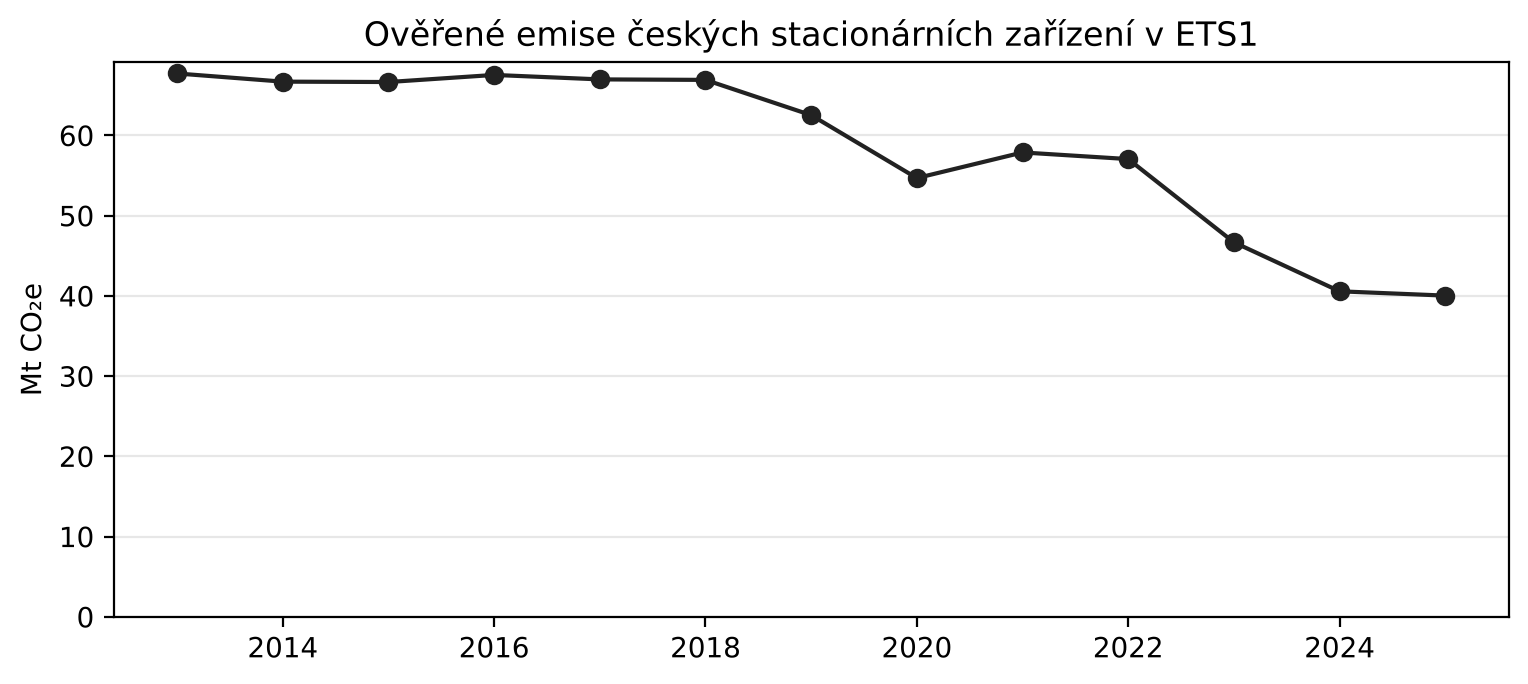

In [13]:
celkem = (E0.sum() / 1e6).rename("Mt CO2e")
vyvoj = pd.DataFrame({"Mt CO2e": celkem.round(2),
                      "zařízení s emisemi": (E0 > 0).sum()})
display(vyvoj.T)

ax = celkem.plot(marker="o", color="#222", figsize=(9, 3.6), title="Ověřené emise českých stacionárních zařízení v ETS1")
ax.set_ylabel("Mt CO₂e"); ax.set_ylim(0); ax.grid(axis="y", alpha=.3); plt.show()

### Výchozí rok: 2013, ne 2005 – proč
* Soubor obsahuje data od 2008, ale **`Read Me` říká, že od 2013 nejsou data srovnatelná s dřívějšími** (rozšíření rozsahu ve fázi III).
  Rok 2005 v souboru vůbec není.
* Zařízení zaniklá před 2013 v souboru chybí; porovnání proti 2008–2012 by tedy nemělo správný základ.
* 2013 je navíc začátek fáze III, vhodný start pro „kolik se uspořilo od té doby“.

### Rok 2025 – upozornění
Extrakce je z **1. 4. 2026**, krátce po zákonném termínu ověřených hlášení (31. 3.). Hlášení za 2025 mohou být neúplná.
Orientační kontrola: kolik zařízení, která v 2024 emitovala, nemá v 2025 žádný údaj?

In [14]:
bez_hlaseni_2025 = (E0[2024] > 0) & E[2025].isna() & ~EXCL[2025]
print(f"Zařízení s emisemi v 2025: {(E0[2025] > 0).sum()} (v 2024: {(E0[2024] > 0).sum()})")
print(f"Zařízení s emisemi v 2024 a bez údaje v 2025: {bez_hlaseni_2025.sum()}")
print(f"Jejich emise v 2024: {E0.loc[bez_hlaseni_2025, 2024].sum()/1e6:.3f} Mt")

Zařízení s emisemi v 2025: 204 (v 2024: 210)
Zařízení s emisemi v 2024 a bez údaje v 2025: 11
Jejich emise v 2024: 0.135 Mt


**Závěr:** počet zařízení klesl o 6, ne dramaticky, a emise zařízení bez údaje za 2025 jsou zanedbatelné. Není důvod
rok 2025 vylučovat, ale zůstává **upozornění: může jít o předběžná data**.

## 5. Rozklad meziroční změny: princip a první pokus

Meziroční změna celkových emisí ΔE = E(t) − E(t−1) je součet změn jednotlivých zařízení. Každé zařízení zařadíme **do právě
jedné** skupiny, takže se součty skupin přesně rovnají celkové změně:

| Složka | Definice | Příspěvek |
|---|---|---|
| **Zavřená** | v t−1 emise > 0, v t emise = 0 (nebo chybí) | −E(t−1) |
| **Nová** | poprvé v historii má emise > 0 | +E(t) |
| **Pokračující** | zbytek | E(t) − E(t−1) |
| *Nejasná, mimo rozsah* | viz dále | |

Původní zadání požadovalo, aby zavřené zařízení mělo navíc **pokles přídělu o více než 15 %**. Zkusíme nejdřív tuto přísnou
verzi (`mode="alokace"`) a podíváme se, co z ní vychází.

### Jak funkce pracuje (čtěte komentáře)

In [15]:
CATS = ["zavrena", "nova", "pokracujici", "nejasne", "mimo_rozsah"]


def rozklad(E, A, EXCL, cz, thr=0.15, mode="vse"):
    """
    Rozklad meziroční změny emisí na složky (zařízení se klasifikuje do právě jedné).

    mode = "vse"      zavřeno = emise klesly na 0 / chybí (kromě 'Excluded')        <- finální volba
           "alokace"  zavřeno = navíc pokles přídělu o více než `thr`; zbytek je „nejasné“
           "posledni" zavřeno = rok t-1 je POSLEDNÍ rok s emisemi > 0 v datech
           "closure"  jako "posledni" a navíc ACCOUNT_CLOSURE != OPEN
    """
    E0, A0 = E.fillna(0.0), A.fillna(0.0)
    pos = E0 > 0
    # "někdy dřív mělo emise > 0": kumulativní součet posunutý o rok (rok t se nedívá sám na sebe)
    ever_before = pos.cumsum(axis=1).shift(1, axis=1).fillna(0) > 0
    last_pos = pos.apply(lambda r: max([y for y in YEARS if r[y]] or [np.nan]), axis=1)
    closure_set = cz["ACCOUNT_CLOSURE"].astype(str).str.upper().ne("OPEN")

    rows = []
    for t in YEARS[1:]:
        p = t - 1
        d = E0[t] - E0[p]                              # změna každého zařízení
        stopped = (E0[p] > 0) & (E0[t] == 0)           # emise zmizely
        excl = stopped & EXCL[t]                       # ... protože je zařízení mimo rozsah ETS
        if mode == "vse":
            closed = stopped & ~excl
        elif mode == "alokace":
            # relativní pokles přídělu; je-li příděl v t-1 nulový, pokles nelze spočítat -> False
            drop = (A0[p] > 0) & ((A0[p] - A0[t]) / A0[p].replace(0, np.nan) > thr)
            closed = stopped & ~excl & drop
        elif mode == "posledni":
            closed = stopped & ~excl & (last_pos == p)
        else:
            closed = stopped & ~excl & (last_pos == p) & closure_set
        unclear = stopped & ~excl & ~closed            # emise zmizely, ale kritérium zavření nesplněno
        new = (E0[t] > 0) & ~ever_before[t]            # poprvé emise > 0
        cat = pd.Series("pokracujici", index=E.index)  # zbytek
        cat[new] = "nova"; cat[closed] = "zavrena"; cat[unclear] = "nejasne"; cat[excl] = "mimo_rozsah"
        rows.append(pd.DataFrame({"rok": t, "kat": cat, "zmena": d, "E_prev": E0[p], "E_t": E0[t]}))
    long = pd.concat(rows).reset_index()


    agg = long.pivot_table(index="rok", columns="kat", values="zmena", aggfunc="sum", fill_value=0.0)
    for k in CATS:
        if k not in agg:
            agg[k] = 0.0
    agg = agg[CATS]
    agg["celkem_zmena"] = E0.sum().diff().reindex(agg.index)
    agg["emise_celkem"] = E0.sum().reindex(agg.index)

    # KONTROLA: složky musí přesně dát celkovou změnu
    assert np.allclose(agg[CATS].sum(axis=1), agg["celkem_zmena"], atol=1e-6), "Složky nesedí na celkovou změnu!"
    return agg, long


agg_strict, long_strict = rozklad(E, A, EXCL, stac, thr=0.15, mode="alokace")
(agg_strict[["zavrena", "nova", "pokracujici", "nejasne", "mimo_rozsah", "celkem_zmena"]] / 1e6).round(2)

kat,zavrena,nova,pokracujici,nejasne,mimo_rozsah,celkem_zmena
rok,,,,,,
2014,-0.02,0.06,-1.06,-0.00,0.0,-1.02
2015,-0.01,0.00,-0.03,-0.00,0.0,-0.05
2016,-0.02,0.01,0.90,-0.00,0.0,0.88
2017,-0.05,0.00,-0.50,-0.00,0.0,-0.56
2018,-0.04,0.00,-0.00,-0.02,0.0,-0.06
2019,-0.07,0.00,-4.33,-0.00,0.0,-4.39
2020,-0.09,0.01,-7.75,-0.01,0.0,-7.84
2021,-0.66,0.01,6.05,-2.21,-0.0,3.20
2022,-0.02,0.00,-0.67,-0.15,0.0,-0.83


### Jak to ověřit na jednom zařízení (ručně)
Vezměte jedno zavřené zařízení a projděte si jeho řádek: kdy emise zmizely, kolik jich bylo, jak se změnil příděl.
Funkce `rozklad` pak musí dát příspěvek přesně −E(t−1).

In [16]:
def radek(id_):
    r = pd.DataFrame({"emise [kt]": (E0.loc[id_] / 1e3).round(1), "příděl [kt]": (A0.loc[id_] / 1e3).round(1)})
    r.insert(0, "Excluded", EXCL.loc[id_])
    return r.T

# Prunéřov 1 (id 126): emise dolů a pak nula; příděl už v 2020 dávno nulový
print(stac.loc[126, "INSTALLATION_NAME"])
display(radek(126))
print("Klasifikace v rozkladu:")
long_strict[(long_strict.INSTALLATION_IDENTIFIER == 126) & (long_strict.rok >= 2019)][["rok", "kat", "zmena", "E_prev", "E_t"]]

ČEZ, a. s. - Elektrárna Prunéřov 1


,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Excluded,False,False,False,False,False,False,False,False,False,False,False,False,False
emise [kt],2534.0,2550.6,2280.0,2143.4,1949.2,2161.8,1906.3,586.2,0.0,0.0,0.0,0.0,0.0
příděl [kt],79.9,66.5,54.4,43.7,34.3,13.7,22.5,8.9,0.0,0.0,0.0,0.0,0.0


Klasifikace v rozkladu:


,rok,kat,zmena,E_prev,E_t
2164,2019,pokracujici,-255433.0,2161781.0,1906348.0
2527,2020,pokracujici,-1320181.0,1906348.0,586167.0
2890,2021,zavrena,-586167.0,586167.0,0.0
3253,2022,pokracujici,0.0,0.0,0.0
3616,2023,pokracujici,0.0,0.0,0.0
3979,2024,pokracujici,0.0,0.0,0.0
4342,2025,pokracujici,0.0,0.0,0.0


## 6. Co jsou „nejasné“ případy a Ledvice 4

V přísné verzi zůstala skupina **„nejasné“**: zařízení, jejichž emise zmizely, ale **příděl neklesl o víc než 15 %**.
Podívejme se, co v ní je a proč.

In [17]:
nejasne = long_strict[long_strict.kat == "nejasne"].copy()
nejasne = nejasne.join(stac[["INSTALLATION_NAME", "ACCOUNT_CLOSURE"]], on="INSTALLATION_IDENTIFIER")
nejasne["příděl_t-1 [kt]"] = [A0.loc[i, t - 1] / 1e3 for i, t in zip(nejasne.INSTALLATION_IDENTIFIER, nejasne.rok)]
nejasne["bez_přídělu"] = nejasne["příděl_t-1 [kt]"] == 0
print(f"Nejasných případů: {len(nejasne)}, jejich emise v t-1: {nejasne.E_prev.sum()/1e6:.2f} Mt")
print(f"  z toho zařízení, která NEMĚLA příděl: {nejasne.bez_přídělu.sum()} ({nejasne[nejasne.bez_přídělu].E_prev.sum()/1e6:.2f} Mt)")
nejasne.sort_values("E_prev", ascending=False).head(8)[["rok", "INSTALLATION_NAME", "E_prev", "příděl_t-1 [kt]", "ACCOUNT_CLOSURE"]].round(0)

Nejasných případů: 22, jejich emise v t-1: 2.39 Mt
  z toho zařízení, která NEMĚLA příděl: 16 (2.38 Mt)


,rok,INSTALLATION_NAME,E_prev,příděl_t-1 [kt],ACCOUNT_CLOSURE
2880,2021,ČEZ - Elektrárna Ledvice 4,2209071.0,0.0,23-DEC-21
2974,2022,"Energotrans, a.s. - Elektrárna Mělník 3",147331.0,0.0,12-APR-23
1725,2018,"TŘINECKÉ ŽELEZÁRNY, a.s.(provoz VT-VÁLCOVNA TRUB)",14013.0,0.0,04-SEP-18
2457,2020,VIADRUS a.s.,5583.0,0.0,30-NOV-20
3749,2024,Kotelna Procter & Gamble Rakovník,4020.0,0.0,05-FEB-25
3712,2024,HELUZ cihlářský průmysl - Cihelna Hevlín,3056.0,12.0,OPEN
612,2015,Teplárna Loučovice,3030.0,3.0,OPEN
4017,2025,CEREPA a.s.,1783.0,1.0,OPEN


### Proč jsou „nejasné“ nejasné
Kritérium „příděl klesl o 15 %“ **nelze spočítat, když zařízení žádný příděl nemělo** (dělení nulou). A to je typicky
**elektrárna**: výrobci elektřiny dostávají od fáze III jen minimum bezplatných povolenek. Skutečné zavření elektrárny tak
kritérium nezachytí. Skupina „nejasné“ je tedy z větší části **artefakt kritéria**, ne skutečná nejistota.

**Proto jste se rozhodla**, že se všechna zařízení, která přestala emitovat (ne `Excluded`), počítají jako **zavřená** (`mode="vse"`).
Původní přísné kritérium necháme jen v citlivostní analýze (sekce 9).

### Největší „nejasný“ případ: Ledvice 4. Je to opravdu zavření?
Největší položka (2,2 Mt) je zařízení *ČEZ – Elektrárna Ledvice 4*. Než ho necháme počítat jako zavřené, podíváme se na emise
všech zařízení s „Ledvice“ v názvu.

In [18]:
led = stac[stac.INSTALLATION_NAME.str.contains("Ledvice", case=False)]
t = (E[YEARS].loc[led.index] / 1e6).round(2)
t.insert(0, "zařízení", led.INSTALLATION_NAME.str[:42])
t["ACCOUNT_CLOSURE"] = led.ACCOUNT_CLOSURE
t

,zařízení,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,ACCOUNT_CLOSURE
INSTALLATION_IDENTIFIER,,,,,,,,,,,,,,,
424,ČEZ - Elektrárna Ledvice 4,0.0,0.05,0.42,0.89,2.09,2.12,2.45,2.21,NaN,NaN,NaN,NaN,NaN,23-DEC-21
121,"ČEZ, a. s. - Elektrárna Ledvice",1.7,1.12,0.71,0.59,0.47,0.52,0.22,0.54,3.78,3.05,2.82,2.74,3.22,OPEN


### Co z toho vidíme
* **Ledvice 4 (id 424)** emise **nabíhají** v letech 2014–2019 (0,05 → 2,45 Mt). Jde o nový blok, ne o dožívající zdroj.
* V roce **2021** emise Ledvic 4 zmizí (účet uzavřen 23. 12. 2021) a **ve stejném roce** skočí hlavní zařízení
  **„ČEZ, a. s. – Elektrárna Ledvice“ (id 121)** z 0,54 na 3,78 Mt, tedy o **3,2 Mt**. To je víc než zmizelo u Ledvic 4.
* Elektrárna samotná nezanikla: je v provozu dál (2025: 3,2 Mt).

**Interpretace:** nejpravděpodobnější vysvětlení je **sloučení dvou instalací v registru**. Emise se přesunuly z jednoho záznamu
do druhého. Není to ani zavření (emise nezmizely), ani úspora (nikdo nic nesnížil). Ponecháme-li oba záznamy zvlášť, uměle
nafoukneme zavírání o 2,2 Mt a o stejnou hodnotu uměle snížíme „pokračující“ (na straně Ledvic vypadá přesun jako nárůst).

**Rozhodnutí:** oba záznamy sečteme a budeme je brát jako **jedno zařízení (společnost)**. Blok Ledvice 4 je tak zařazen jako **rozšíření kapacity** existující elektrárny, tedy do kategorie „pokračující“ (ne jako nové zařízení ani zavření). Sečtou se emise i příděly po letech.
Alternativa by byla udržovat „převod“ jako zvláštní složku; sečtení je ale jednodušší, průhlednější a dává stejný závěr.

> **Upozornění:** že jde o sloučení v registru, je závěr z dat (načasování + velikost skoku). Vhodné ověřit u provozovatele (ČEZ)
> nebo v historii instalace v EUTL. V kódu je sloučení vedeno jako **explicitní, snadno vypnutelná konstanta** `SLOUCENI`.

### Existují podobné případy jinde? (heuristika)
Prohledáme všechna zavřená zařízení nad 10 kt: pro každé hledáme jiné zařízení, které (a) **ve stejném roce vzrostlo o ≥ 50 %
zavřených emisí** a (b) **sdílí výrazný kus názvu** (bez obecných slov typu „elektrárna“, „kotelna“).

In [19]:
agg_vse_bez, long_vse_bez = rozklad(E, A, EXCL, stac, mode="vse")      # zatím bez přesunů
GEN = set("elektrárna teplárna kotelna výtopna energie energo plynová uhelná spol provozovna závod areál centrální zdroj "
          "výroba teplárenská provoz divize czech republic česká české průmyslové služby kotelny energetické centrum "
          "tepelné hospodářství".split())

def tokeny(nazev):
    t = re.findall(r"[a-zá-žA-ZÁ-Ž0-9]{5,}", str(nazev).lower())
    return {x for x in t if x not in GEN and not x.isdigit()}

nm = stac.INSTALLATION_NAME
nalezy = []
for _, r in long_vse_bez[long_vse_bez.kat == "zavrena"].iterrows():
    if r.E_prev < 10_000:
        continue
    tk = tokeny(nm[r.INSTALLATION_IDENTIFIER])
    for j in E0.index:
        if j == r.INSTALLATION_IDENTIFIER:
            continue
        dj = E0.loc[j, r.rok] - E0.loc[j, r.rok - 1]
        if dj >= 0.5 * r.E_prev and tokeny(nm[j]) & tk:
            nalezy.append((r.rok, nm[r.INSTALLATION_IDENTIFIER][:38], round(r.E_prev / 1e6, 2), nm[j][:38], round(dj / 1e6, 2), sorted(tokeny(nm[j]) & tk)))
pd.DataFrame(nalezy, columns=["rok", "zavřené zařízení", "jeho emise [Mt]", "zařízení, které vzrostlo", "nárůst [Mt]", "shoda v názvu"])

,rok,zavřené zařízení,jeho emise [Mt],"zařízení, které vzrostlo",nárůst [Mt],shoda v názvu
0,2018,"TŘINECKÉ ŽELEZÁRNY, a.s.(provoz VT-VÁL",0.01,Třinecké železárny,0.07,"[třinecké, železárny]"
1,2021,ČEZ - Elektrárna Ledvice 4,2.21,"ČEZ, a. s. - Elektrárna Ledvice",3.25,[ledvice]
2,2021,"ČEZ, a. s. - Elektrárna Prunéřov 1",0.59,"ČEZ, a. s. - Elektrárna Prunéřov 2",0.65,[prunéřov]
3,2025,Cukrovar Vrbátky - uhelná kotelna,0.03,Tereos TTD - Cukrovar Dobrovice,0.02,[cukrovar]
4,2025,Veolia Energie - Teplárna Českoslovens,0.03,Veolia Energie - Elektrárna Třebovice,0.04,[veolia]
5,2025,Veolia Energie - Teplárna Českoslovens,0.03,Veolia Energie - Teplárna Olomouc,0.03,[veolia]


### Vyhodnocení nálezů (ručně)
* **Ledvice 4 → Ledvice (2021)**: shoda názvu, skok 3,25 Mt ≥ 2,21 Mt, uzavřený účet ve stejném roce → **sloučit** (bereme).
* *Prunéřov 1 → Prunéřov 2 (2021)*: jsou to **samostatné elektrárny**; k nárůstu Prunéřova 2 o 0,65 Mt došlo kvůli obecnému
  oživení výroby 2021. Shoda je jen v názvu místa → **nesloučíme**.
* Třinecké železárny (0,01 Mt) a drobné teplárny (Veolia, Cukrovar): zanedbatelné nebo shoda jen v názvu firmy → **nesloučíme**.

Heuristika tedy slouží k **vyhledání kandidátů**, rozhodnutí je ruční. Proto je seznam sloučení `SLOUCENI` explicitní:

In [20]:
# {INSTALLATION_IDENTIFIER zdroje: INSTALLATION_IDENTIFIER cíle}: zdroj se sečte do cíle
SLOUCENI = {424: 121}      # Ledvice 4 -> ČEZ, a. s. - Elektrárna Ledvice
SLOUCENY_NAZEV = {121: "ČEZ - Elektrárna Ledvice (včetně Ledvic 4)"}


def sluc(zar):
    """Sečte emise a příděly zařízení ze SLOUCENI do cílového zařízení; zdrojový řádek se odstraní."""
    zar = zar.copy()
    cols = [c for c in zar.columns if re.match(r"^(VERIFIED_EMISSIONS|ALLOCATION\w*)_\d{4}$", str(c))]
    for src, dst in SLOUCENI.items():
        vals = zar.loc[[src, dst], cols]
        assert not vals.astype(str).apply(lambda x: x.str.strip().str.lower().eq("excluded")).any().any()
        zar.loc[dst, cols] = vals.apply(pd.to_numeric, errors="coerce").sum(min_count=1)   # NaN + NaN zůstane NaN (ne 0)
        zar.loc[dst, "INSTALLATION_NAME"] = SLOUCENY_NAZEV.get(dst, zar.loc[dst, "INSTALLATION_NAME"])
        zar = zar.drop(index=src)
    return zar


celkem_pred = E0.sum().sum()
stac = sluc(stac)                                   # od teď se pracuje s 362 zařízeními
E, A, EXCL, E0, A0 = priprav_matice(stac)
assert np.isclose(E0.sum().sum(), celkem_pred)      # sloučení nezměnilo celkové emise ani o tunu
print(f"Zařízení po sloučení: {len(stac)}")
(E.loc[[121]] / 1e6).round(2)

Zařízení po sloučení: 362


,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
INSTALLATION_IDENTIFIER,,,,,,,,,,,,,
121,1.7,1.16,1.13,1.47,2.55,2.63,2.67,2.74,3.78,3.05,2.82,2.74,3.22


Řádek výše je nově „ČEZ – Elektrárna Ledvice (včetně Ledvic 4)“: v letech 2014–2020 obsahuje i emise Ledvic 4, takže křivka
je hladká a 2021 už není skok. Celkové emise ČR se nezměnily (assert), jen se jinak rozdělují mezi zařízení.

Nutné upozornění k notebooku: **od této chvíle jsou všechny výsledky počítané se sloučenými Ledvicemi**. Sekce 5 a začátek
sekce 6 ukazují původní stav před sloučením, aby bylo vidět, proč k němu došlo.

## 7. Finální rozklad, kumulativní pohled, kontroly

Finální nastavení: `mode="vse"` (všechna zastavená zařízení jsou zavřená, kromě `Excluded`), na datech se sloučenými Ledvicemi.
Funkce uvnitř **assertem** ověřuje, že součet složek přesně sedí na celkovou změnu každého roku.

In [21]:
agg, long = rozklad(E, A, EXCL, stac, mode="vse")
tab_rok = (agg[["zavrena", "nova", "pokracujici", "nejasne", "mimo_rozsah", "celkem_zmena", "emise_celkem"]] / 1e6).round(2)
tab_rok

kat,zavrena,nova,pokracujici,nejasne,mimo_rozsah,celkem_zmena,emise_celkem
rok,,,,,,,
2014,-0.02,0.01,-1.01,0.0,0.0,-1.02,66.70
2015,-0.02,0.00,-0.03,0.0,0.0,-0.05,66.65
2016,-0.02,0.01,0.90,0.0,0.0,0.88,67.53
2017,-0.05,0.00,-0.50,0.0,0.0,-0.56,66.98
2018,-0.06,0.00,-0.00,0.0,0.0,-0.06,66.91
2019,-0.07,0.00,-4.33,0.0,0.0,-4.39,62.52
2020,-0.10,0.01,-7.75,0.0,0.0,-7.84,54.68
2021,-0.66,0.01,3.84,0.0,-0.0,3.20,57.87
2022,-0.16,0.00,-0.67,0.0,0.0,-0.83,57.04


### Jak číst tabulku
* `zavrena`, `nova`, `pokracujici` = příspěvky složek ke změně emisí (v Mt; záporné = pokles).
* `mimo_rozsah` je zanedbatelné (jednotky kt): zařízení, která měla emise a pak se objevil `Excluded`.
* `nejasne` je teď prázdné (všechna zastavená zařízení jsou „zavřená“).

### Kumulativní změna oproti 2013
Součet ročních příspěvků od 2014 do roku t. Podíl složek pak počítáme z celkového poklesu 2013 → 2025.

In [22]:
kum = agg[CATS].cumsum()
kum["celkem"] = kum.sum(axis=1)
# kontrola: kumulativní změna = emise_t - emise_2013
assert np.allclose(kum["celkem"], agg["emise_celkem"] - E0[BASE].sum(), atol=1e-6)

pokles = -kum["celkem"].iloc[-1]
podily = pd.Series({
    "pokračující zařízení (snižování emisí)": -kum["pokracujici"].iloc[-1] / pokles * 100,
    "zavřená zařízení": -kum["zavrena"].iloc[-1] / pokles * 100,
    "mimo rozsah ETS": -kum["mimo_rozsah"].iloc[-1] / pokles * 100,
    "nová zařízení (zmírňují pokles)": -kum["nova"].iloc[-1] / pokles * 100,
})
assert abs(podily.sum() - 100) < 1e-6      # kontrola na nezaokrouhlených hodnotách
podily = podily.round(1)                    # zaokrouhlení jen pro zobrazení (součet pak může vyjít 99,9–100,1)
print(f"Celkový pokles 2013 → 2025: {pokles/1e6:.2f} Mt ({pokles/E0[BASE].sum()*100:.0f} % emisí z 2013)\n")
print("Podíl na poklesu [%]:"); print(podily.to_string()); print("Součet zaokrouhlených hodnot:", round(podily.sum(), 1))
(kum / 1e6).round(2)

Celkový pokles 2013 → 2025: 27.68 Mt (41 % emisí z 2013)

Podíl na poklesu [%]:
pokračující zařízení (snižování emisí)    91.5
zavřená zařízení                           8.9
mimo rozsah ETS                            0.0
nová zařízení (zmírňují pokles)           -0.3
Součet zaokrouhlených hodnot: 100.1


kat,zavrena,nova,pokracujici,nejasne,mimo_rozsah,celkem
rok,,,,,,
2014,-0.02,0.01,-1.01,0.0,0.0,-1.02
2015,-0.03,0.01,-1.04,0.0,0.0,-1.06
2016,-0.06,0.02,-0.15,0.0,0.0,-0.18
2017,-0.11,0.02,-0.65,0.0,0.0,-0.74
2018,-0.17,0.02,-0.66,0.0,0.0,-0.80
2019,-0.24,0.02,-4.98,0.0,0.0,-5.19
2020,-0.33,0.03,-12.73,0.0,0.0,-13.04
2021,-0.99,0.04,-8.89,0.0,-0.0,-9.84
2022,-1.15,0.05,-9.56,0.0,-0.0,-10.67


**Interpretace.** Pokles ETS1 v ČR je z drtivé většiny dán tím, že **provozy, které stále fungují, vypouštějí méně**
(odstavování uhelných bloků, přechod na plyn/biomasu, nižší výroba, efektivita). Zavírání celých zařízení tvoří menšinu.
Pozor: „pokračující“ obsahuje i **částečné odstavení velkých provozů** (např. vysoká pec v Liberty Ostrava, emise klesly o 1,2 Mt,
ale zařízení nemá nulu), takže „skutečné snižování“ je spíš **horní odhad**.

## 8. Okrajové případy a jak jsou ošetřeny

Zde je jedno místo, kde si můžete zkontrolovat každý okrajový případ ze zadání.

| Případ | Ošetření | Kde se dá ověřit |
|---|---|---|
| NaN vs 0 u emisí | NaN → 0 pro součty; druh chybějící hodnoty se uchovává (`EXCL`, `E.isna()`) | sekce 3 |
| NaN vs 0 u přídělu | NaN → 0 (dle `Read Me` „nebyl přidělen“); jen pomocné kritérium | sekce 5–6 |
| zařízení zmizí z datasetu | v souboru **řádky nechybí**, zařízení mají prázdné hodnoty → bere se jako zastavení | níže |
| emise 0 a příděl neklesl | původně „nejasné“; nově počítáno jako zavřené (rozhodnutí uživatelky) | sekce 6 |
| změna rozsahu (`Excluded`) | zvláštní složka `mimo_rozsah`, nepočítá se ani jako úspora, ani jako zavření | níže |
| sloučení / přečíslování | `SLOUCENI` (Ledvice 4 + Ledvice se sečtou) | sekce 6 |
| nové činnosti (např. spalování odpadu od 2024) | nová zařízení se zobrazují zvlášť, viz sekce 11 | sekce 11 |
| rok 2025 předběžný | upozornění + kontrola počtu zařízení | sekce 4 |

### 8a) Zařízení s „mezerou“ v emisích
Zařízení s emisemi > 0, pak 0/NaN a pak znovu > 0. Při `mode="vse"` by se zařadila nejprve jako zavřená a po návratu jako „pokračující“.
Kolik takových případů je a jak velké?

In [23]:
pos = E0 > 0
mezery = []
for i in E0.index[pos.any(axis=1)]:
    p = pos.loc[i].values
    f, l = np.argmax(p), len(p) - 1 - np.argmax(p[::-1])
    if not p[f:l + 1].all():
        mezery.append((i, stac.loc[i, "INSTALLATION_NAME"][:45], round(E0.loc[i].max() / 1e3, 1)))
print(f"Zařízení s mezerou v řadě: {len(mezery)}")
pd.DataFrame(mezery, columns=["id", "název", "maximum emisí [kt]"])

Zařízení s mezerou v řadě: 6


,id,název,maximum emisí [kt]
0,377,EOP Distribuce - Farářství,0.0
1,71,EOP Distribuce - Teplárna Pardubice,0.0
2,378,EOP Distribuce - ZVU,0.4
3,90,Energotrans - Výtopna Třeboradice,1.3
4,87,Pražská teplárenská - Výtopna Krč,3.3
5,298,Thermoservis spol. s r. o. - Kotelna CZT Nymb,0.5


Jde o drobné případy (největší má maximum jen několik kt), takže jejich chybná klasifikace nemůže změnit závěr.

### 8b) Kdo je `Excluded` a proč se nepočítá jako zavření

In [24]:
excl_any = EXCL.any(axis=1)
print(f"Zařízení, která byla někdy 'Excluded': {excl_any.sum()}")
print(f"Jejich emise v posledním roce PŘED vyřazením: {sum(E0.loc[i, :][E0.loc[i, :] > 0].iloc[-1] if (E0.loc[i, :] > 0).any() else 0 for i in E0.index[excl_any]) / 1e3:.1f} kt (celkem)")
print(f"Součet složky 'mimo_rozsah' v rozkladu: {agg['mimo_rozsah'].sum()/1e6:.4f} Mt")

Zařízení, která byla někdy 'Excluded': 13
Jejich emise v posledním roce PŘED vyřazením: 9.7 kt (celkem)
Součet složky 'mimo_rozsah' v rozkladu: -0.0046 Mt


`Excluded` zařízení mají (až na pár kt) **nulové emise ještě před vyřazením**; dopad na rozklad je zanedbatelný, ale
logika je připravena, aby se případný nenulový případ neměl počítat jako zavření ani úspora.

### 8c) Rok 2025 a „nová“ zařízení z roku 2024–2025 (změna rozsahu)
Zadání upozorňovalo na nové činnosti zařazené do ETS (spalování odpadu od 2024). Podíváme se, co se v ČR objevilo:

In [25]:
nova_p = long[long.kat == "nova"].join(stac[["INSTALLATION_NAME", "MAIN_ACTIVITY_TYPE_CODE"]], on="INSTALLATION_IDENTIFIER")
nova_p[nova_p.rok >= 2024][["rok", "INSTALLATION_NAME", "MAIN_ACTIVITY_TYPE_CODE", "E_t"]].round(0)

,rok,INSTALLATION_NAME,MAIN_ACTIVITY_TYPE_CODE,E_t
3859,2024,Technologický komplex Energy nest,20,1861.0
4096,2025,Kalcinační jednotka Vřesová,99,6937.0
4159,2025,Plynová kotelna Prunéřov,20,2462.0
4189,2025,"Saint-Gobain Construction Products CZ a.s., Rigips",34,23521.0
4201,2025,Synthesia Nitrocellulose,38,618.0
4292,2025,Výroba sádry a sádrokartonových desek,34,13826.0


**Závěr:** žádná velká nová zařízení se spalováním odpadu se v ČR v datech neobjevila; nová zařízení z 2024–2025 jsou
drobná (celkem ~0,05 Mt). Změna rozsahu tedy výsledek nezkresluje. U 2025 se doporučuje ověřit, zda sádrokartonová
zařízení nejsou jen změnou povolení.

## 9. Citlivostní analýza

**Otázka:** mění se závěr, když změníme prahy a definici zavření? Porovnáme:
* přísné kritérium přes příděl s prahem **10 %, 15 %, 25 %** (zbytek zůstává „nejasné“),
* **finální** definici (všechna zastavená),
* **„poslední rok s emisemi > 0“** (zavřeno, když už po roce t−1 nejsou žádné emise v datech),
* totéž + `ACCOUNT_CLOSURE != OPEN`.

Všechny varianty běží na datech se sloučenými Ledvicemi.

In [26]:
def citlivost(E, A, EXCL, cz):
    var = [("FINÁLNÍ: všechna zastavená = zavřená", dict(mode="vse")),
           ("jen příděl: práh 10 %", dict(thr=0.10, mode="alokace")),
           ("jen příděl: práh 15 %", dict(thr=0.15, mode="alokace")),
           ("jen příděl: práh 25 %", dict(thr=0.25, mode="alokace")),
           ("poslední rok s emisemi > 0 v datech", dict(mode="posledni")),
           ("poslední rok s emisemi > 0 a účet != OPEN", dict(mode="closure"))]
    out = []
    for nm_, kw in var:
        a, _ = rozklad(E, A, EXCL, cz, **kw)
        c = a[CATS].sum()
        pokles = -c.sum()
        out.append({"varianta": nm_,
                    "zavřená [%]": 100 * -c["zavrena"] / pokles,
                    "nejasné [%]": 100 * -c["nejasne"] / pokles,
                    "pokračující [%]": 100 * -c["pokracujici"] / pokles,
                    "nová [%]": 100 * -c["nova"] / pokles})
    return pd.DataFrame(out).round(1)

cit = citlivost(E, A, EXCL, stac)
cit

,varianta,zavřená [%],nejasné [%],pokračující [%],nová [%]
0,FINÁLNÍ: všechna zastavená = zavřená,8.9,-0.0,91.5,-0.3
1,jen příděl: práh 10 %,8.2,0.6,91.5,-0.3
2,jen příděl: práh 15 %,8.2,0.7,91.5,-0.3
3,jen příděl: práh 25 %,8.2,0.7,91.5,-0.3
4,poslední rok s emisemi > 0 v datech,8.9,0.0,91.5,-0.3
5,poslední rok s emisemi > 0 a účet != OPEN,8.4,0.4,91.5,-0.3


### Jak číst
* Podíl **pokračujících** zařízení je ve **všech** variantách stejný (~91,5 %). Jde o rozdíl mezi vším, co se počítá jako zavřené
  nebo nejasné.
* **Zavřená + nejasná** dohromady dávají vždy ~9 % poklesu. Podle definice se jen **přelévá** mezi „zavřená“ a „nejasná“.
* Práh 10 % / 15 % / 25 % **na výsledku nic nemění**, protože zavřená zařízení přišla o příděl téměř celý (pokles blízko 100 %);
  hranice 15 % je tedy pro rozklad nepodstatná.

**Závěr je robustní:** zavírání zařízení tvoří řádově 8–9 % poklesu, ostatní (~91 %) je snižování v provozech, které dál fungují.

## 10. Největší zavřená zařízení a společnosti

### 10a) 10 největších zavřených zařízení (kontrola, že kritérium dává smysl)
Pro každé zavřené zařízení: název, sektor, emise v posledním roce provozu, rok zavření, stav účtu a **možná upozornění**
(stejný držitel má nové zařízení v okolních letech → možné přečíslování; účet stále `OPEN` → možná jen odstávka).

In [27]:
def top10(long, cz, n=10):
    z = long[long.kat == "zavrena"].copy()
    z = z.join(cz[["INSTALLATION_NAME", "IDENTIFIER_IN_REG", "MAIN_ACTIVITY_TYPE_CODE", "ACCOUNT_CLOSURE"]], on="INSTALLATION_IDENTIFIER")
    z["sektor"] = z.MAIN_ACTIVITY_TYPE_CODE.map(SEKTOR)
    nova = long[long.kat == "nova"].join(cz[["IDENTIFIER_IN_REG"]], on="INSTALLATION_IDENTIFIER")
    poz = []
    for _, r in z.iterrows():
        p = []
        if len(nova[(nova.IDENTIFIER_IN_REG == r.IDENTIFIER_IN_REG) & nova.rok.between(r.rok - 1, r.rok + 1)]):
            p.append("stejný držitel má nové zařízení – možné přečíslování")
        if str(r.ACCOUNT_CLOSURE).upper() == "OPEN":
            p.append("účet stále OPEN – možná jen odstávka")
        poz.append("; ".join(p))
    z["poznámka"] = poz
    z = z.sort_values("E_prev", ascending=False).head(n)
    return pd.DataFrame({"zařízení": z.INSTALLATION_NAME.values, "sektor": z.sektor.values,
                         "emise v posl. roce [kt]": (z.E_prev / 1e3).round(1).values,
                         "poslední rok provozu": (z.rok - 1).values, "rok zavření": z.rok.values,
                         "účet": z.ACCOUNT_CLOSURE.values, "poznámka": z["poznámka"].values})

top10(long, stac)

,zařízení,sektor,emise v posl. roce [kt],poslední rok provozu,rok zavření,účet,poznámka
0,TAMEH Czech,Energetika a teplo,1110.9,2023,2024,08-JAN-25,
1,"ČEZ, a. s. - Elektrárna Prunéřov 1",Energetika a teplo,586.2,2020,2021,17-JAN-24,
2,"Energotrans, a.s. - Elektrárna Mělník 3",Energetika a teplo,147.3,2021,2022,12-APR-23,
3,Liberty Ostrava a.s.,Energetika a teplo,39.6,2024,2025,OPEN,účet stále OPEN – možná jen odstávka
4,Tereos TTD - Moravský Lihovar Kojetín kotelna,Energetika a teplo,34.3,2019,2020,22-OCT-21,
5,Veolia Energie - Teplárna Československé armády,Energetika a teplo,32.8,2024,2025,OPEN,účet stále OPEN – možná jen odstávka
6,Cukrovar Vrbátky - uhelná kotelna,Energetika a teplo,30.6,2024,2025,04-MAR-26,
7,Teplárna Písek,Energetika a teplo,30.5,2020,2021,15-JUL-22,
8,HOLOUBEK ENERGO - Teplárna divize Tevex,Energetika a teplo,26.5,2018,2019,22-JAN-20,
9,Devro - plynová kotelna,Energetika a teplo,19.2,2023,2024,08-JAN-25,


**Jak kontrolovat:** projděte řádek po řádku. Velká zařízení jsou důvěryhodná (TAMEH Czech, Prunéřov 1, Mělník 3: shodují se
s uzavřeným účtem). Menší s příznakem `OPEN` jsou kandidáti na „jen odstávka“ a doporučuje se je ověřit.

Pozn.: zavření zařízení nemusí znamenat zánik firmy – mnoho jich jsou **kotelny uvnitř podniků** nebo části teplárenské
sítě, které se přeřadily jinam.

### 10b) Největší uzavřené společnosti (trvalý zánik emisí)
Zde nehledáme „zavření v daném roce“, ale zařízení, která **po nějakém roce už nehlásí žádné emise** (poslední rok s emisemi ≤ 2024).
Seskupíme je podle držitele (`IDENTIFIER_IN_REG`). Řadíme podle **maxima emisí**, protože emise v posledním roce bývají
po postupném odstavení nízké. 

In [28]:
def uzavrene_spolecnosti(E, EXCL, cz, long):
    E0 = E.fillna(0.0); pos = E0 > 0
    radky = []
    for i in E0.index[pos.any(axis=1)]:
        last = max(y for y in YEARS if pos.loc[i, y])
        if last >= YEARS[-1]:
            continue                                  # stále má emise
        radky.append(dict(id=i, posledni_rok=last, E_posledni=E0.loc[i, last], E_max=E0.loc[i].max(),
                          rok_zavreni=last + 1))
    z = pd.DataFrame(radky).join(cz[["INSTALLATION_NAME", "IDENTIFIER_IN_REG", "MAIN_ACTIVITY_TYPE_CODE", "ACCOUNT_CLOSURE"]], on="id")
    z["sektor"] = z.MAIN_ACTIVITY_TYPE_CODE.map(SEKTOR)
    z["ucet_open"] = z.ACCOUNT_CLOSURE.astype(str).str.upper().eq("OPEN")
    g = z.groupby("IDENTIFIER_IN_REG").agg(
        zarizeni=("id", "size"),
        max_emisi_Mt=("E_max", lambda v: v.sum() / 1e6),
        emise_posledni_rok_Mt=("E_posledni", lambda v: v.sum() / 1e6),
        rok_zavreni=("rok_zavreni", lambda v: str(min(v)) if min(v) == max(v) else f"{min(v)}–{max(v)}"),
        ucet_open=("ucet_open", "any"),
    ).sort_values("max_emisi_Mt", ascending=False).reset_index().rename(columns={"IDENTIFIER_IN_REG": "držitel"})
    return g

uzavrene = uzavrene_spolecnosti(E, EXCL, stac, long)
uzavrene.head(12).round(3)

,držitel,zarizeni,max_emisi_Mt,emise_posledni_rok_Mt,rok_zavreni,ucet_open
0,Liberty Ostrava a.s.,2,3.312,0.049,2025,True
1,ČEZ - Elektrárna Prunéřov 1,1,2.551,0.586,2021,False
2,TAMEH Czech,1,2.489,1.111,2024,False
3,Energotrans - Elektrárna Mělník 3,1,1.899,0.147,2022,False
4,CZT Příbram,1,0.231,0.000,2024,True
5,Veolia Energie - Teplárna Čs. armády,1,0.175,0.033,2025,True
6,CARMEUSE - Vápenka Mokrá,1,0.136,0.000,2025,True
7,SKATLOP a.s.,1,0.074,0.001,2025,True
8,Teplárna Písek,1,0.069,0.030,2021,False
9,Teplárna Ostrov,1,0.057,0.008,2021,True


**Upozornění:** název držitele je text z registru, firmy ze stejné skupiny s různým názvem se nesčítají (např. *ČEZ – Prunéřov 1* a
*ČEZ – Ledvice*). U **Liberty Ostrava** je účet stále `OPEN`: jde o zavření provozu (postupné odstavení vysoké pece), ne
nutně zánik firmy. Součet maxim zařízení u firmy s více zařízeními není maximum firmy v jednom roce.

## 11. Nová zařízení

**Definice:** zařízení, které **poprvé** vykázalo emise > 0 v letech 2014–2025. Všechna, co emitovala už v 2013, jsou „stará“.

**Co je důležité vědět:**
* „nové“ je jen **první rok**: příspěvek nového zařízení je E(t) v roce, kdy poprvé emituje. Pokud pak roste, další růst
  se počítá jako „pokračující“. Skutečný růst nových kapacit tedy rozklad **podhodnocuje** (typicky velký blok, jehož emise po spuštění nabíhají několik let, jako byly Ledvice 4, které ale nyní sčítáme s Ledvicemi).
* 2013 je základ; zařízení, která v 2013 emitovala, jsou „stará“.

In [29]:
def nova_zarizeni(E, cz):
    E0 = E.fillna(0.0); pos = E0 > 0
    radky = []
    for i in E0.index[pos.any(axis=1)]:
        f = min(y for y in YEARS if pos.loc[i, y])
        if f == YEARS[0]:
            continue
        radky.append(dict(id=i, rok_vzniku=f, E_prvni_rok=E0.loc[i, f], E_max=E0.loc[i].max(), E_2025=E0.loc[i, 2025],
                          posledni_rok=max(y for y in YEARS if pos.loc[i, y])))
    n = pd.DataFrame(radky).join(cz[["INSTALLATION_NAME", "MAIN_ACTIVITY_TYPE_CODE"]], on="id")
    n["sektor"] = n.MAIN_ACTIVITY_TYPE_CODE.map(SEKTOR)
    n["stav"] = np.where(n.posledni_rok == YEARS[-1], "v provozu 2025", "ukončeno")
    return n.sort_values("E_max", ascending=False).reset_index(drop=True)

nz = nova_zarizeni(E, stac)
print(f"Nových zařízení od 2014: {len(nz)}; jejich emise v 2025: {nz.E_2025.sum()/1e6:.3f} Mt = {nz.E_2025.sum()/E0[2025].sum()*100:.2f} % emisí ČR")
print("\nPočet po letech:", nz.groupby("rok_vzniku").size().to_dict())
nz.head(10)[["INSTALLATION_NAME", "sektor", "rok_vzniku", "E_max", "E_2025", "stav"]].round(0)

Nových zařízení od 2014: 19; jejich emise v 2025: 0.103 Mt = 0.26 % emisí ČR

Počet po letech: {2014: 4, 2015: 2, 2016: 2, 2017: 1, 2020: 2, 2021: 1, 2022: 1, 2024: 1, 2025: 5}


,INSTALLATION_NAME,sektor,rok_vzniku,E_max,E_2025,stav
0,"TŘINECKÉ ŽELEZÁRNY, a.s.(provoz VT-VÁLCOVNA TRUB)",Energetika a teplo,2014,24944.0,0.0,ukončeno
1,"Saint-Gobain Construction Products CZ a.s., Rigips",Minerální vlna a sádra,2025,23521.0,23521.0,v provozu 2025
2,Nexen Tire Europe s.r.o.,Energetika a teplo,2021,21509.0,21509.0,v provozu 2025
3,PK ELE,Energetika a teplo,2014,20419.0,11026.0,v provozu 2025
4,Výroba sádry a sádrokartonových desek,Minerální vlna a sádra,2025,13826.0,13826.0,v provozu 2025
5,Spalovací zařízení kotelny,Energetika a teplo,2015,9853.0,5250.0,v provozu 2025
6,PZP Dambořice,Energetika a teplo,2016,8847.0,7874.0,v provozu 2025
7,Pittsburgh Corning CR,Sklo,2016,7300.0,5921.0,v provozu 2025
8,Kalcinační jednotka Vřesová,Jiné (opt-in),2025,6937.0,6937.0,v provozu 2025
9,Výrobní linky formalínu,Chemie,2020,5634.0,2149.0,v provozu 2025


**Závěr:** nová zařízení jsou malá (žádné nepřekročilo 25 kt ročně). K celkovému poklesu 27,7 Mt přispěla jen ~0,1 Mt. Pět zařízení z roku 2025 (dvě sádrokartonová, kalcinační jednotka aj.)
je vhodné ověřit: může jít o změnu povolení či rozsahu místo nových kapacit.

## 12. Grafy

Níže jsou tři grafy. Hlavní vstupy jsou tabulky `agg`, `kum`, `uzavrene` a `nz` z předchozích sekcí. Kód grafů je delší,
protože obsahuje kosmetiku (popisky, barvy, rozložení); **důležité je jen to, jaká data do grafu vstupují**.

**Principy:**
* barvy jsou z **barvoslepě bezpečné** palety (Okabe–Ito): modrá = pokračující, oranžová = zavřená, zelená = nová,
* **jedna osa y** v každém panelu (celkové emise jsou proto v samostatném panelu nad rozkladem, ne na druhé ose),
* skupina „mimo rozsah“ (několik kt) se nezobrazuje.

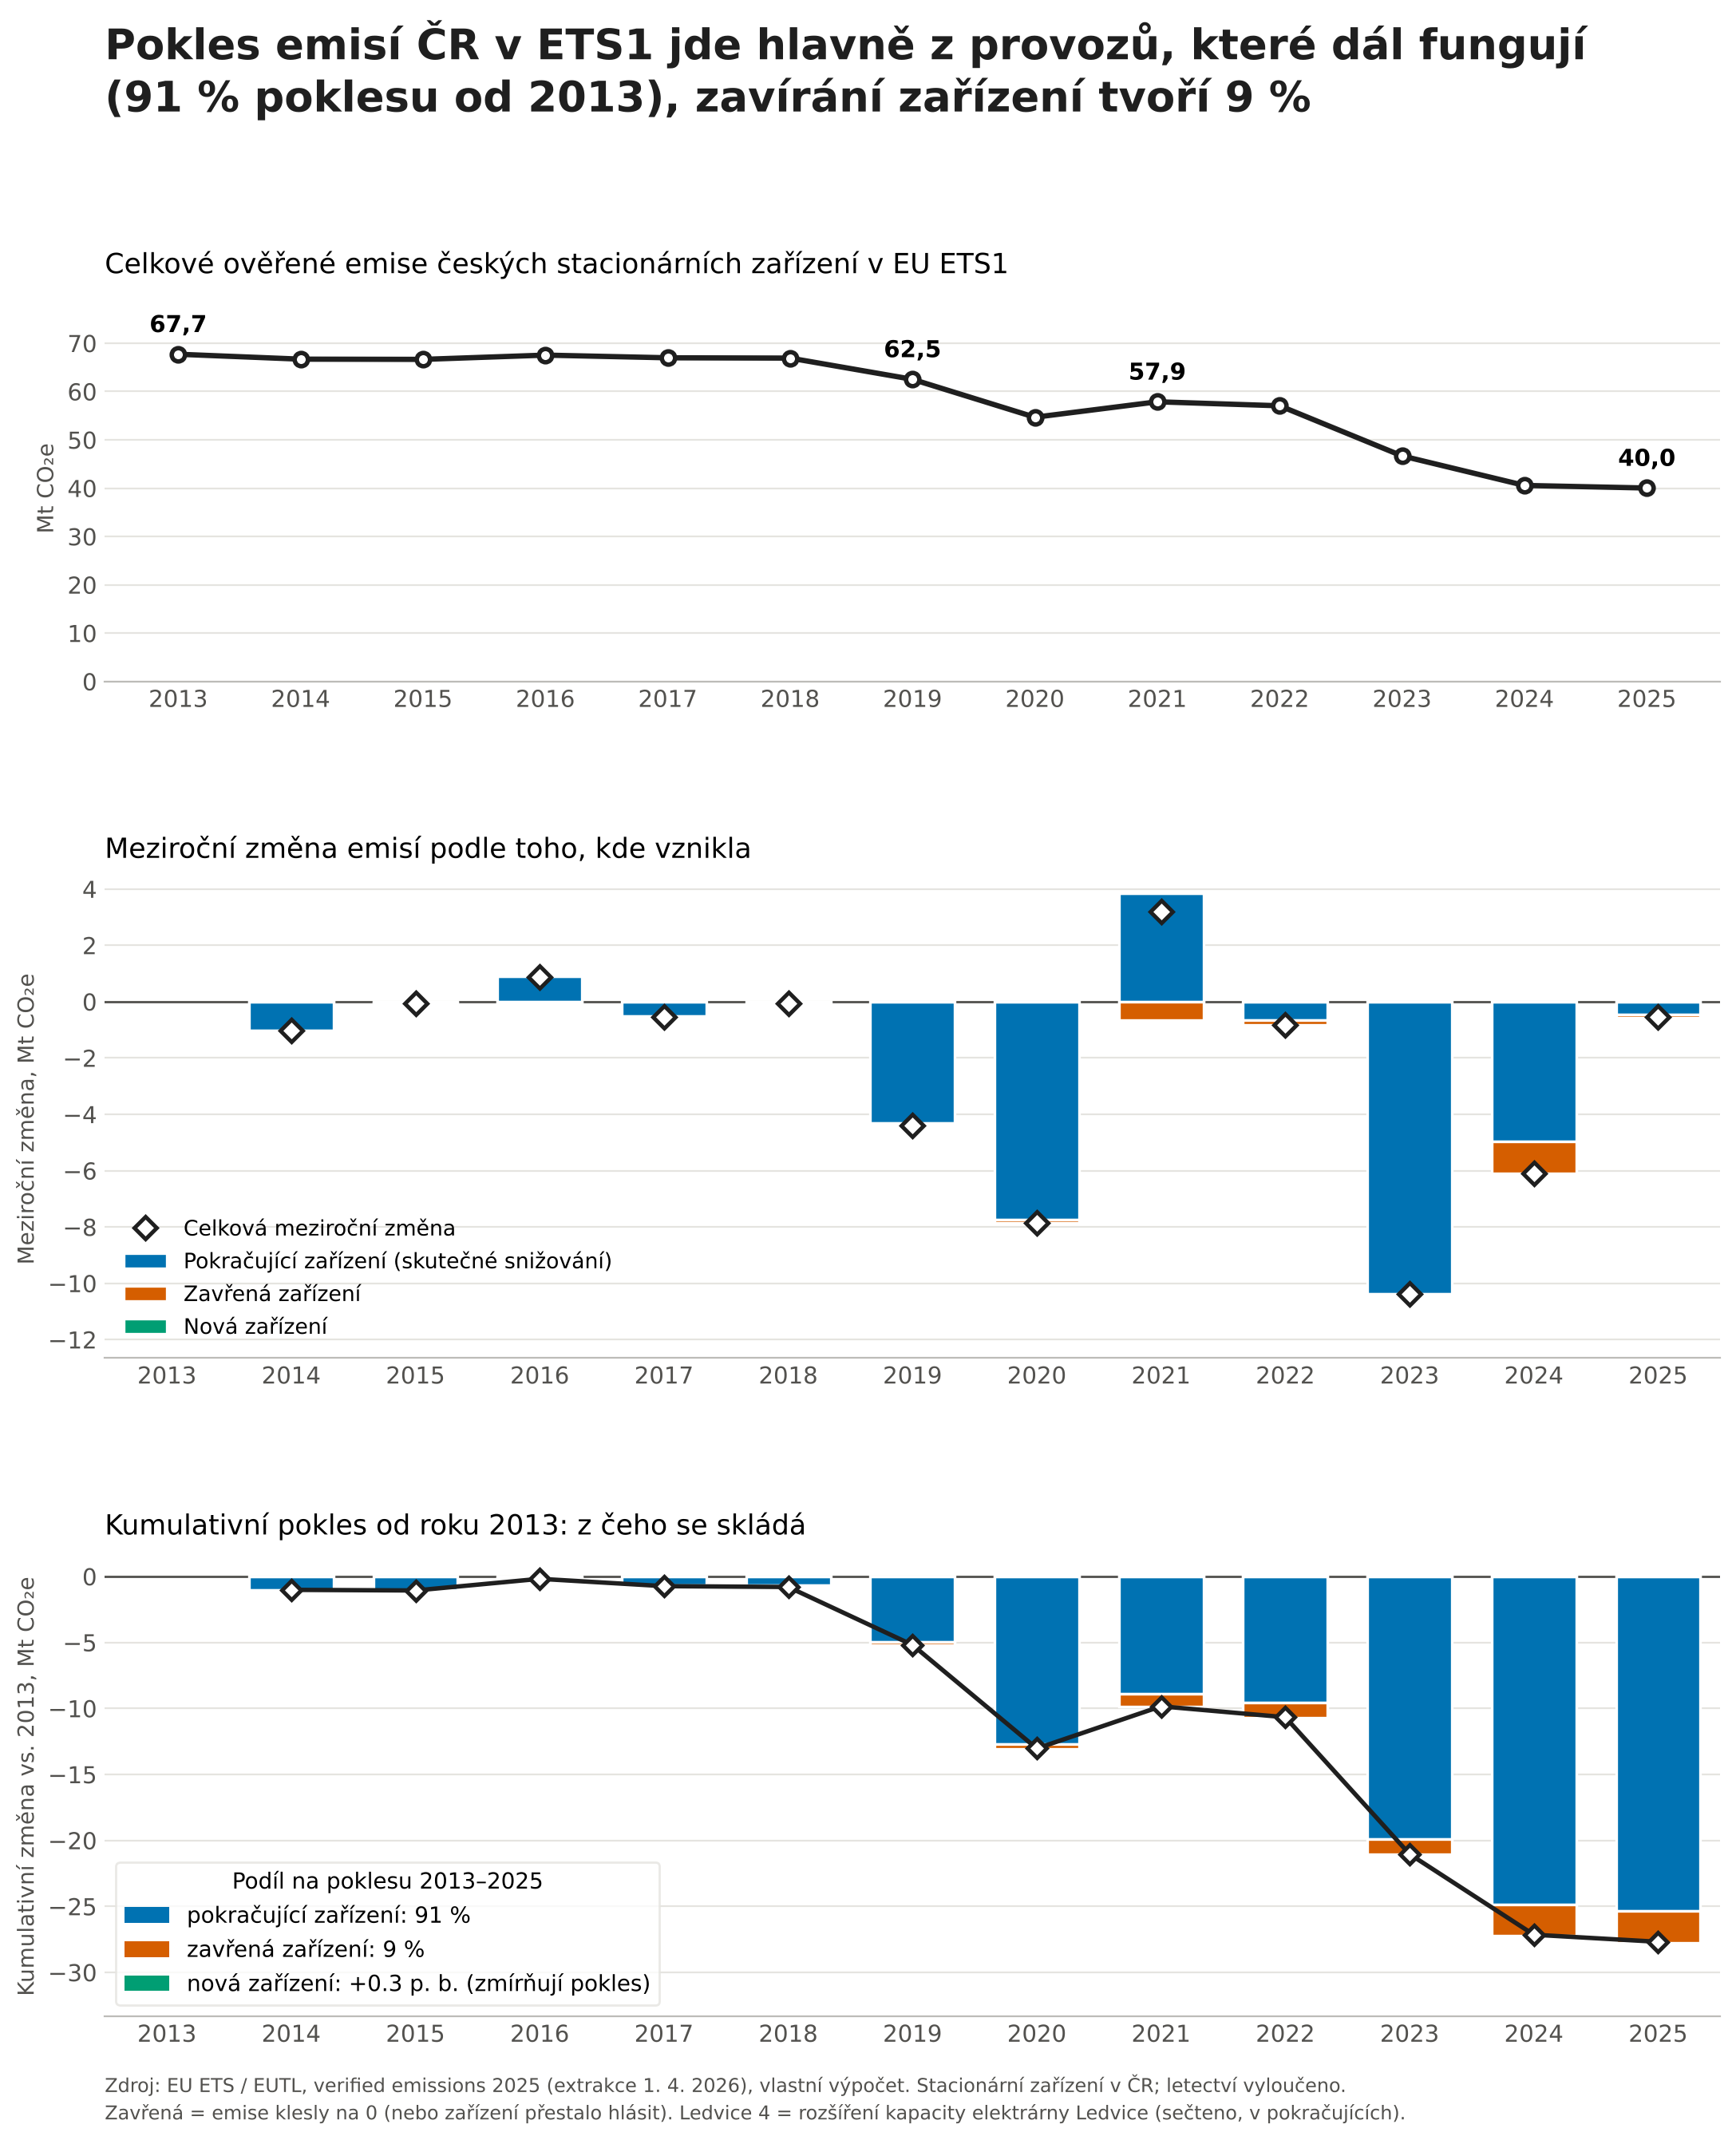

In [30]:
COL = {"zavrena": "#D55E00", "nova": "#009E73", "pokracujici": "#0072B2", "nejasne": "#8C8C8C"}
INK, INK2, GRID = "#1f1f1f", "#52514e", "#e5e4e0"

def styl(ax):
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#bdbcb8")
    ax.tick_params(colors=INK2, length=0, labelsize=10.5)
    ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)

def ulozit(fig, nazev):
    if EXPORT:
        OUT.mkdir(exist_ok=True)
        fig.savefig(OUT / f"{nazev}.png", dpi=300, facecolor="white"); fig.savefig(OUT / f"{nazev}.svg", facecolor="white")

def graf_hlavni(agg, kum):
    cz_ = lambda x: str(x).replace(".", ",")
    pokles = -kum["celkem"].iloc[-1]
    sh = {c: -kum[c].iloc[-1] / pokles * 100 for c in ["pokracujici", "zavrena", "nova"]}
    cats = ["pokracujici", "zavrena", "nova"]
    yrs = list(agg.index)
    fig, axes = plt.subplots(3, 1, figsize=(11.5, 14), gridspec_kw={"height_ratios": [1.05, 1.3, 1.25], "hspace": .45})
    fig.subplots_adjust(left=.085, right=.965, top=.84, bottom=.07)
    fig.text(.085, .965, f"Pokles emisí ČR v ETS1 jde hlavně z provozů, které dál fungují\n({sh['pokracujici']:.0f} % poklesu od 2013), "
             f"zavírání zařízení tvoří {sh['zavrena']:.0f} %", fontsize=19, fontweight="bold", color=INK, va="top")
    # panel 1: celkové emise
    ax = axes[0]; styl(ax)
    tot = pd.concat([pd.Series({BASE: E0[BASE].sum()}), agg["emise_celkem"]]) / 1e6
    ax.plot(tot.index, tot.values, color=INK, lw=2.4, marker="o", ms=6, mfc="white", mew=2)
    for y in (BASE, 2019, 2021, 2025):
        ax.annotate(cz_(f"{tot[y]:.1f}"), (y, tot[y]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10.5, fontweight="bold")
    ax.set_ylim(0, tot.max() * 1.18); ax.set_xticks(range(BASE, 2026)); ax.set_ylabel("Mt CO₂e", color=INK2)
    ax.set_title("Celkové ověřené emise českých stacionárních zařízení v EU ETS1", loc="left", fontsize=12.5, pad=10)
    # panel 2: meziroční změna po složkách
    ax = axes[1]; styl(ax)
    pos_b = np.zeros(len(yrs)); neg_b = np.zeros(len(yrs))
    for c in cats:
        v = agg[c].values / 1e6
        ax.bar(yrs, v, bottom=np.where(v >= 0, pos_b, neg_b), width=.68, color=COL[c], edgecolor="white", linewidth=1.2, zorder=3,
               label={"pokracujici": "Pokračující zařízení (skutečné snižování)", "zavrena": "Zavřená zařízení", "nova": "Nová zařízení"}[c])
        pos_b += np.where(v >= 0, v, 0); neg_b += np.where(v < 0, v, 0)
    ax.plot(yrs, agg["celkem_zmena"] / 1e6, ls="none", marker="D", ms=7, color=INK, mfc="white", mew=1.8, zorder=5, label="Celková meziroční změna")
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(BASE, 2026)); ax.set_xlim(BASE - .5, 2025.5)
    ax.set_ylim(min(neg_b.min(), (agg["celkem_zmena"] / 1e6).min()) * 1.22, pos_b.max() * 1.12)
    ax.set_ylabel("Meziroční změna, Mt CO₂e", color=INK2); ax.legend(loc="lower left", frameon=False, fontsize=9.6)
    ax.set_title("Meziroční změna emisí podle toho, kde vznikla", loc="left", fontsize=12.5, pad=10)
    # panel 3: kumulativně
    ax = axes[2]; styl(ax)
    pos_b = np.zeros(len(yrs)); neg_b = np.zeros(len(yrs))
    for c in cats:
        v = kum[c].values / 1e6
        ax.bar(yrs, v, bottom=np.where(v >= 0, pos_b, neg_b), width=.68, color=COL[c], edgecolor="white", linewidth=1.2, zorder=3)
        pos_b += np.where(v >= 0, v, 0); neg_b += np.where(v < 0, v, 0)
    ax.plot(yrs, kum["celkem"] / 1e6, color=INK, lw=2, marker="D", ms=6, mfc="white", mew=1.8, zorder=5)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(BASE, 2026)); ax.set_xlim(BASE - .5, 2025.5)
    ax.set_ylim(min(neg_b.min(), kum["celkem"].min() / 1e6) * 1.2, 1.5)
    ax.set_ylabel("Kumulativní změna vs. 2013, Mt CO₂e", color=INK2)
    ax.set_title("Kumulativní pokles od roku 2013: z čeho se skládá", loc="left", fontsize=12.5, pad=10)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(fc=COL["pokracujici"], label=f"pokračující zařízení: {sh['pokracujici']:.0f} %"),
                       Patch(fc=COL["zavrena"], label=f"zavřená zařízení: {sh['zavrena']:.0f} %"),
                       Patch(fc=COL["nova"], label=f"nová zařízení: {-sh['nova']:+.1f} p. b. (zmírňují pokles)")],
              title="Podíl na poklesu 2013–2025", loc="lower left", fontsize=10, frameon=True, facecolor="white", edgecolor=GRID)
    fig.text(.085, .02, "Zdroj: EU ETS / EUTL, verified emissions 2025 (extrakce 1. 4. 2026), vlastní výpočet. Stacionární zařízení v ČR; letectví vyloučeno.\n"
             "Zavřená = emise klesly na 0 (nebo zařízení přestalo hlásit). Ledvice 4 = rozšíření kapacity elektrárny Ledvice (sečteno, v pokračujících).",
             fontsize=8.6, color=INK2, va="bottom", linespacing=1.5)
    return fig

fig = graf_hlavni(agg, kum); ulozit(fig, "ets_cz_rozklad"); plt.show()

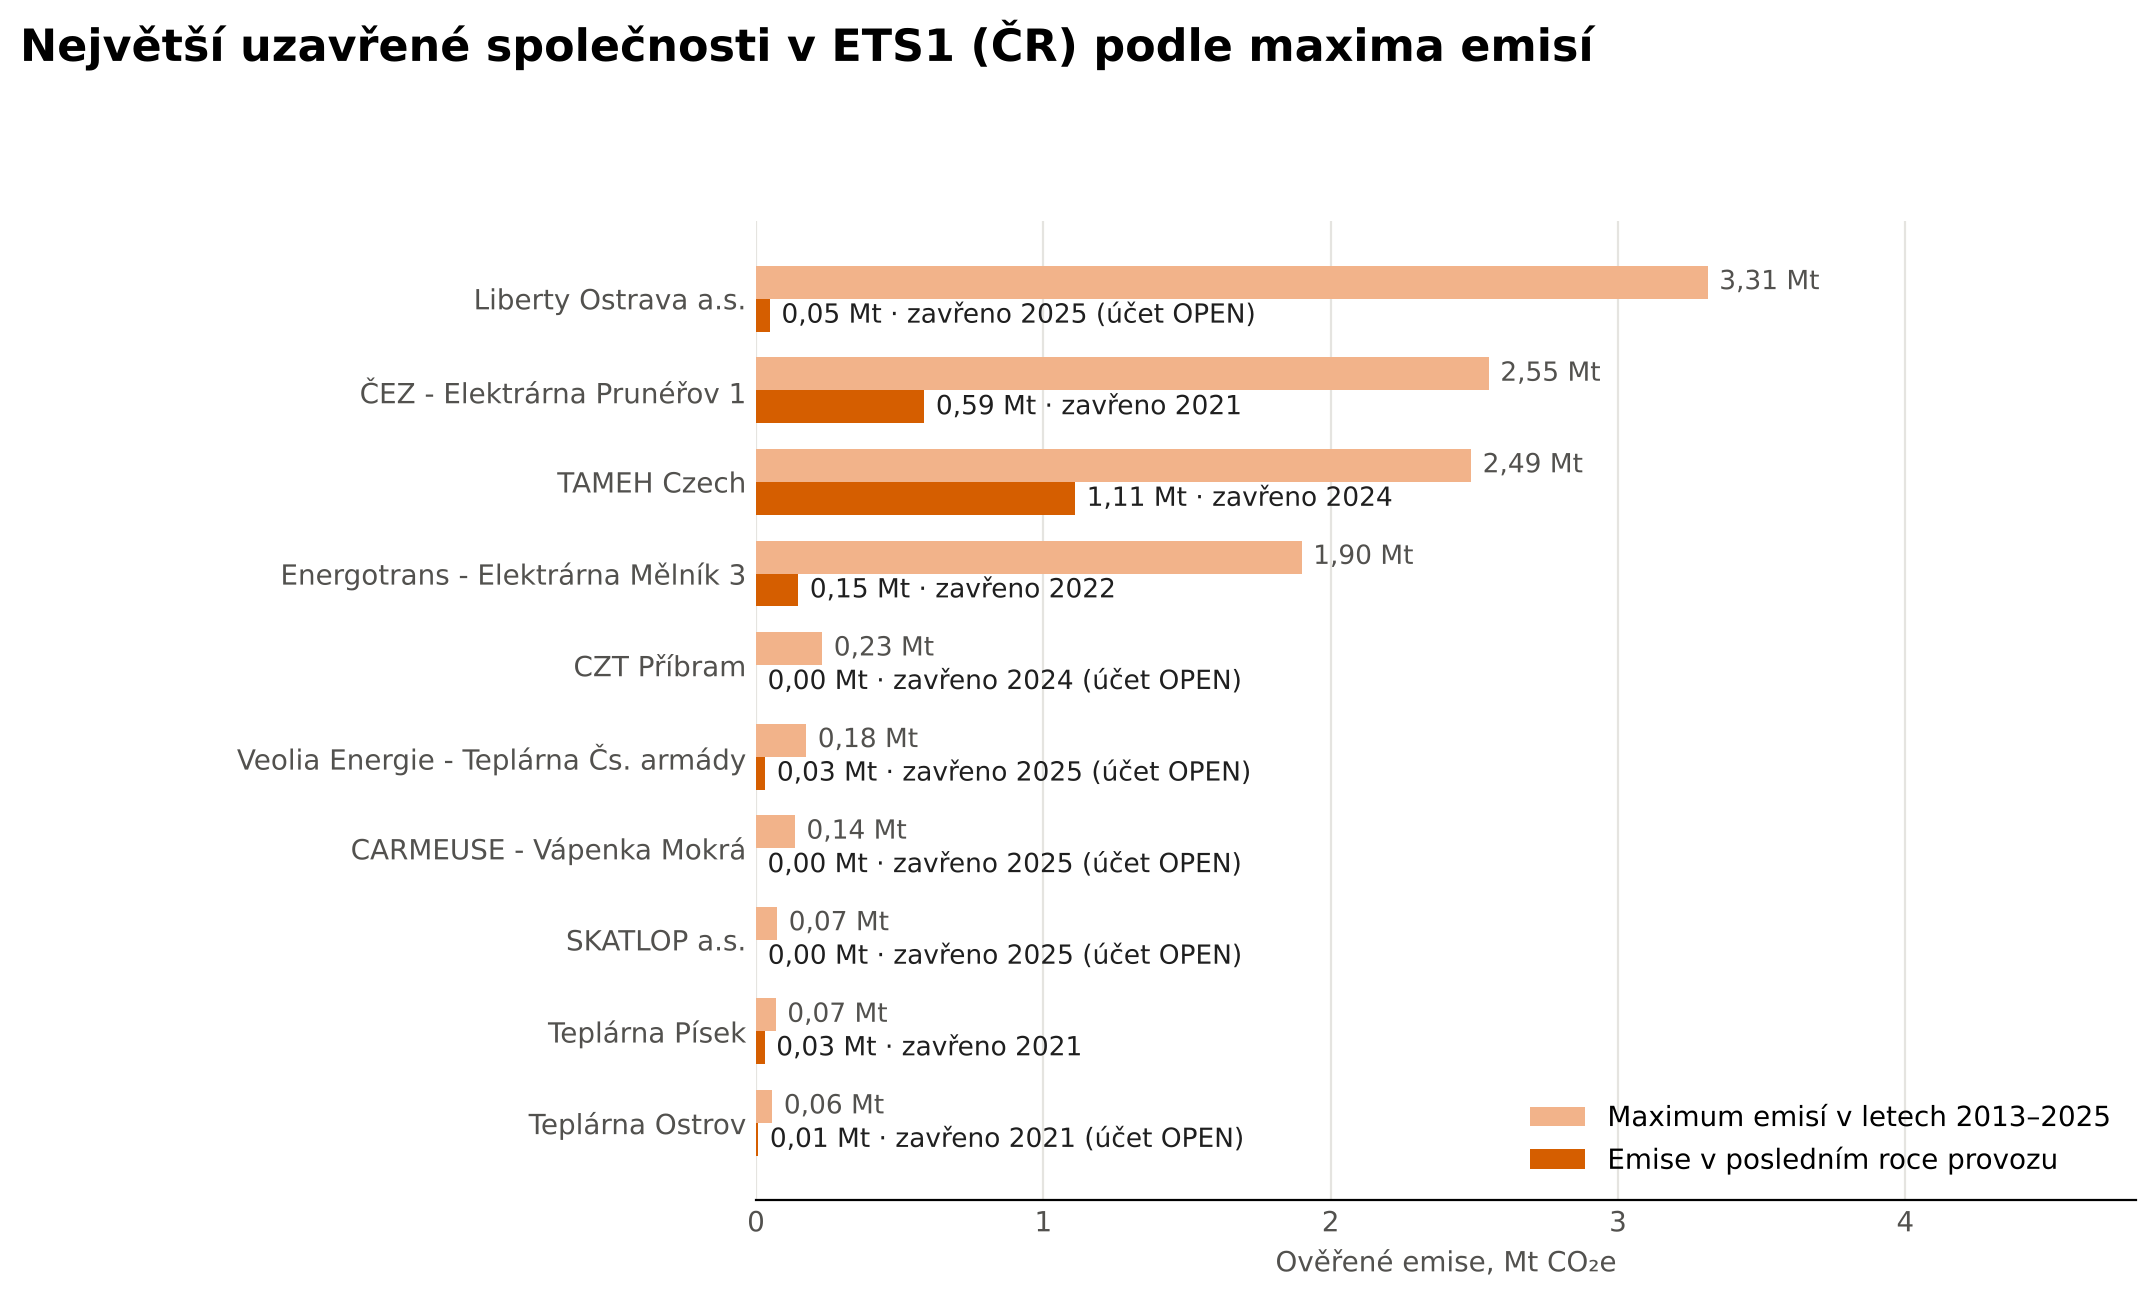

In [31]:
def graf_uzavrene(g, n=10):
    t = g.head(n).iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(11.5, 7.2)); fig.subplots_adjust(left=.34, right=.94, top=.82, bottom=.14)
    y = np.arange(len(t)); h = .36
    ax.barh(y + h / 2, t.max_emisi_Mt, height=h, color="#F2B38A", zorder=3, label="Maximum emisí v letech 2013–2025")
    ax.barh(y - h / 2, t.emise_posledni_rok_Mt, height=h, color=COL["zavrena"], zorder=3, label="Emise v posledním roce provozu")
    for yy, r in enumerate(t.itertuples()):
        ax.text(r.max_emisi_Mt + .04, yy + h / 2, f"{r.max_emisi_Mt:.2f} Mt".replace(".", ","), va="center", fontsize=9.5, color=INK2)
        ax.text(r.emise_posledni_rok_Mt + .04, yy - h / 2, f"{r.emise_posledni_rok_Mt:.2f} Mt · zavřeno {r.rok_zavreni}".replace(".", ",") + (" (účet OPEN)" if r.ucet_open else ""),
                va="center", fontsize=9.5, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(t["držitel"]); ax.set_xlim(0, t.max_emisi_Mt.max() * 1.45)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True); ax.tick_params(colors=INK2, length=0)
    ax.set_xlabel("Ověřené emise, Mt CO₂e", color=INK2); ax.legend(loc="lower right", frameon=False)
    fig.text(.02, .96, "Největší uzavřené společnosti v ETS1 (ČR) podle maxima emisí", fontsize=16, fontweight="bold", va="top")
    return fig

fig = graf_uzavrene(uzavrene); ulozit(fig, "ets_cz_top_uzavrene"); plt.show()

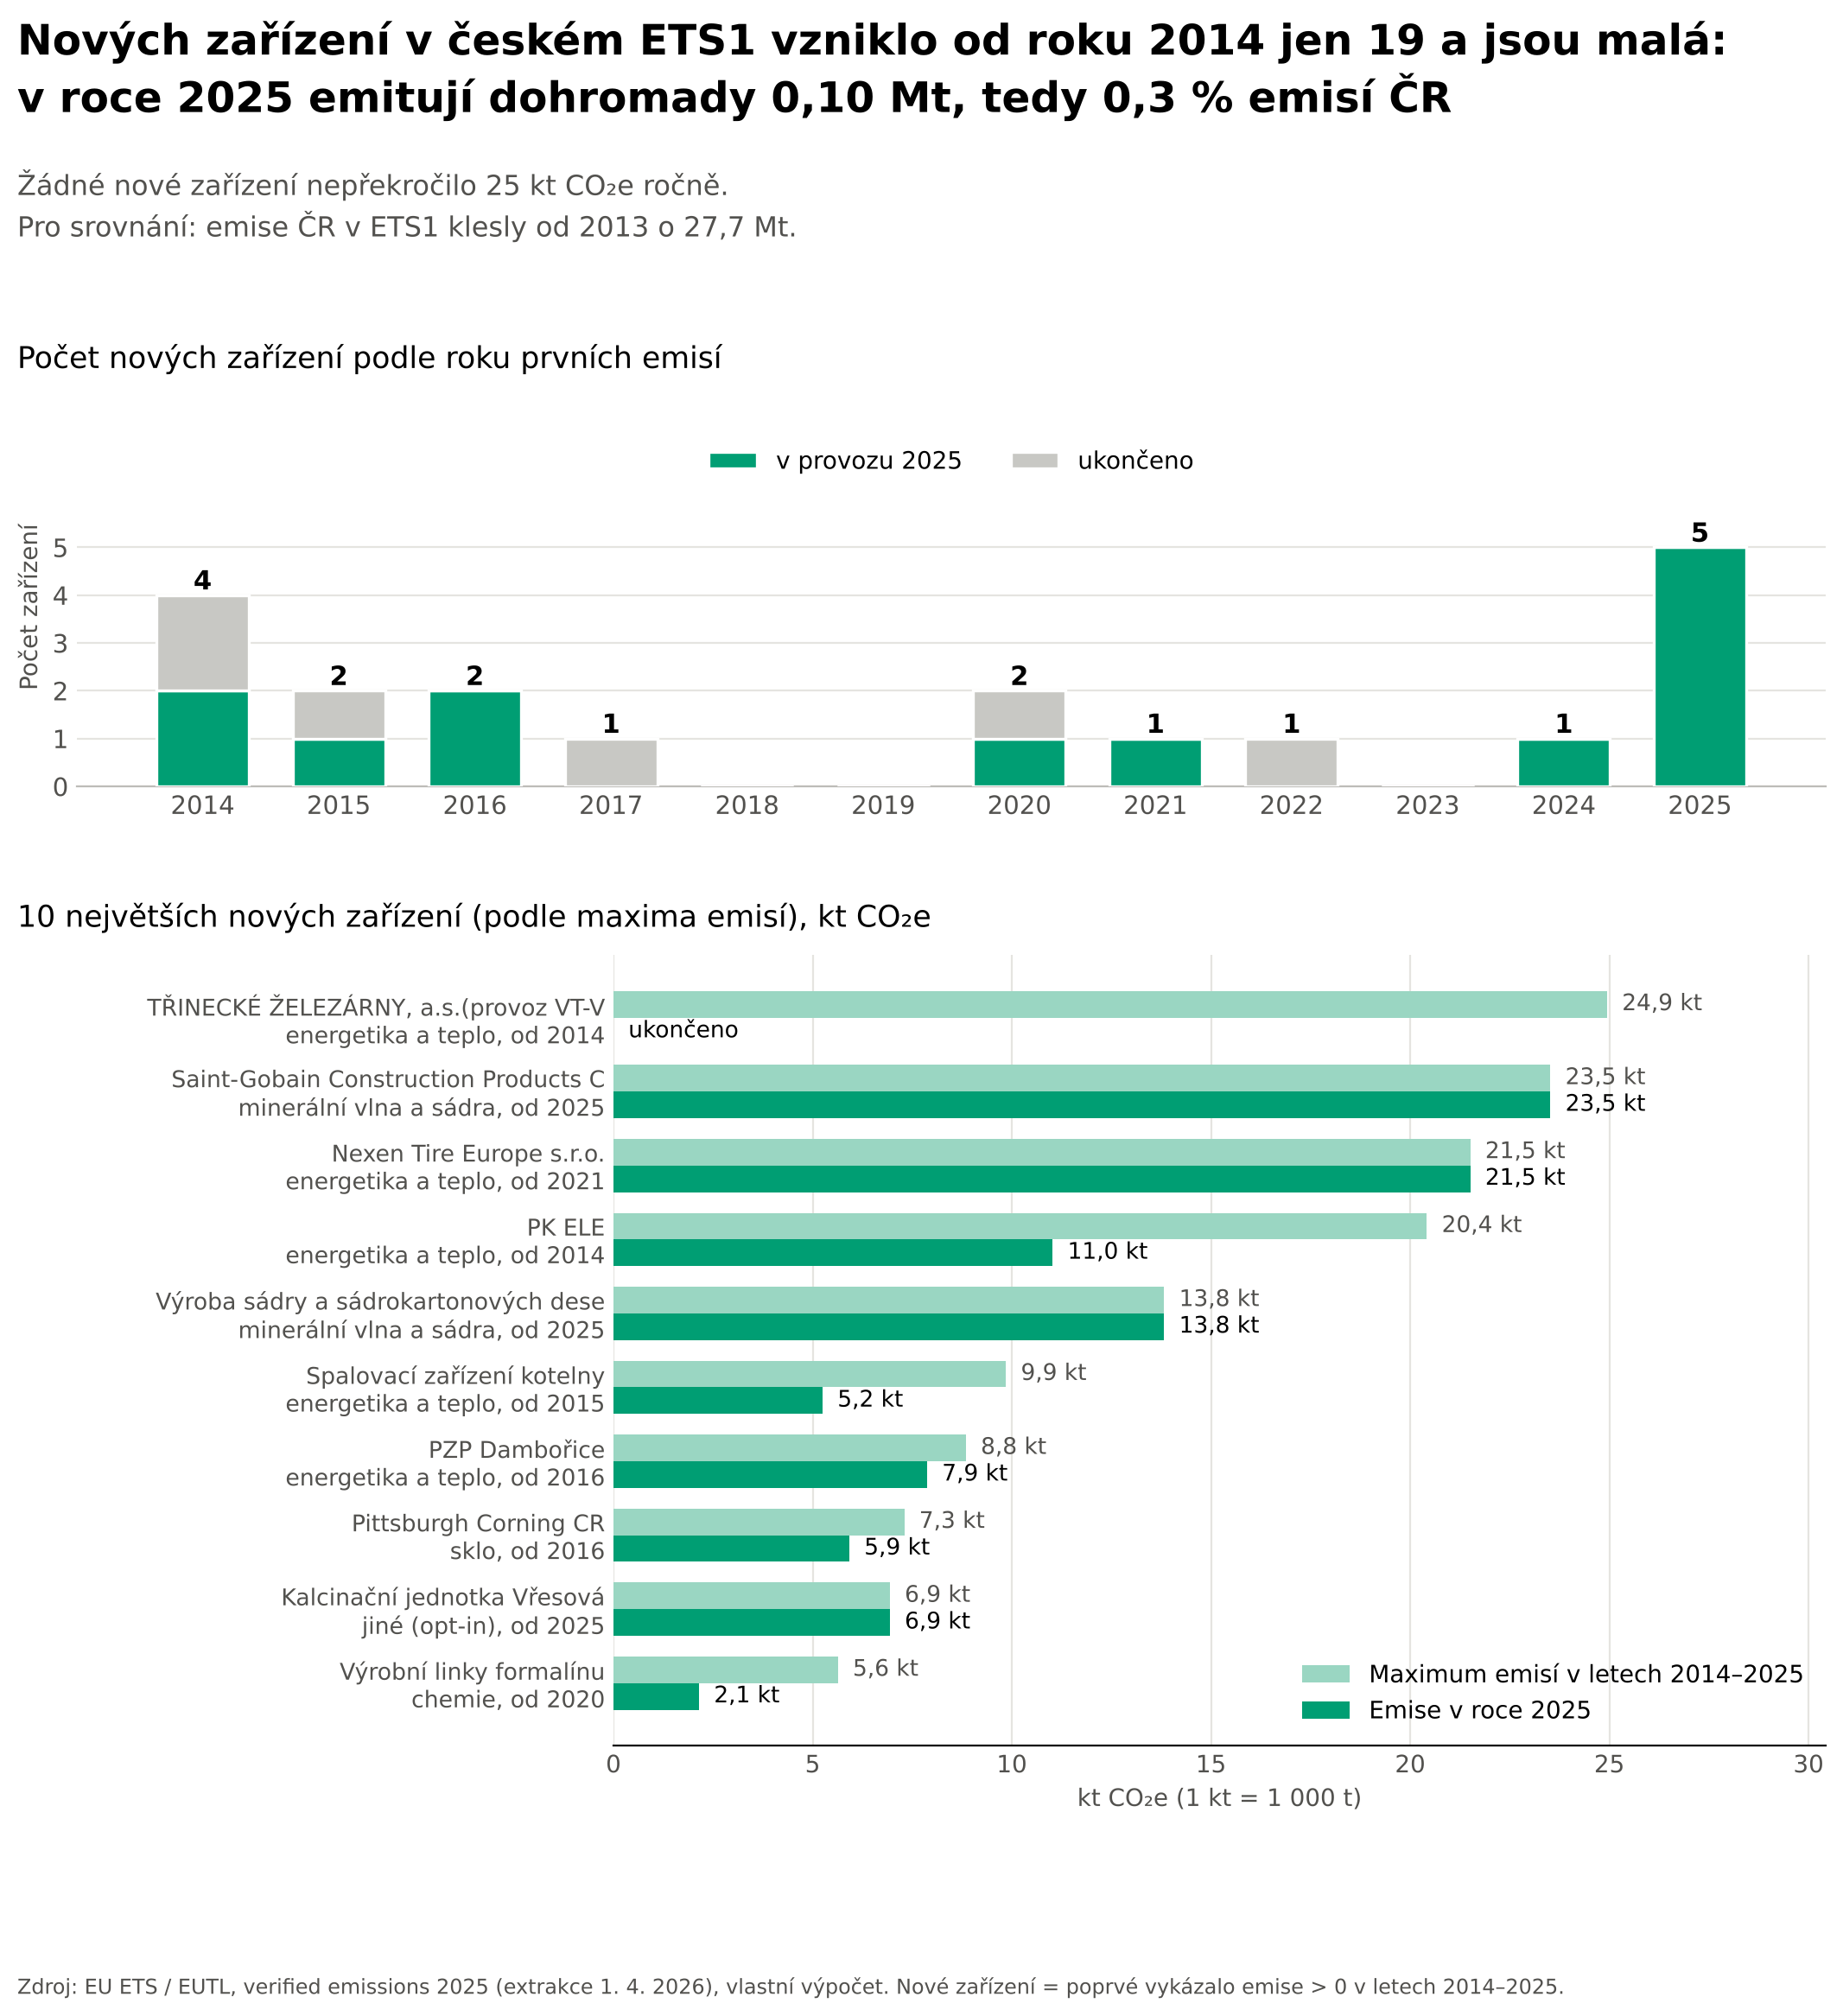

In [32]:
def graf_nova(n, e_total_2025, top=10):
    G, GL, GG = COL["nova"], "#9AD6C2", "#C8C8C4"
    cz_ = lambda x: str(x).replace(".", ",")
    por = n.groupby("rok_vzniku").size().reindex(range(YEARS[1], YEARS[-1] + 1), fill_value=0)
    barva = {"v provozu 2025": G, "ukončeno": GG}
    e25 = n.E_2025.sum()
    fig = plt.figure(figsize=(11.5, 12.2))
    fig.text(.04, .965, f"Nových zařízení v českém ETS1 vzniklo od roku 2014 jen {len(n)} a jsou malá:\n"
             f"v roce 2025 emitují dohromady {cz_(f'{e25/1e6:.2f}')} Mt, tedy {cz_(f'{100*e25/e_total_2025:.1f}')} % emisí ČR",
             fontsize=17.5, fontweight="bold", va="top")
    fig.text(.04, .895, f"Žádné nové zařízení nepřekročilo {n.E_max.max()/1e3:.0f} kt CO₂e ročně.\n"
             "Pro srovnání: emise ČR v ETS1 klesly od 2013 o 27,7 Mt.", fontsize=11.5, color=INK2, va="top", linespacing=1.5)
    ax = fig.add_axes([.07, .60, .88, .17]); spodek = np.zeros(len(por))
    for st, c in barva.items():
        v = n[n.stav == st].groupby("rok_vzniku").size().reindex(por.index, fill_value=0)
        if v.sum():
            ax.bar(por.index, v.values, bottom=spodek, color=c, width=.68, edgecolor="white", linewidth=1.2, label=st, zorder=3)
            spodek += v.values
    for x, v in por.items():
        if v: ax.text(x, v + .12, str(int(v)), ha="center", fontsize=11, fontweight="bold")
    ax.set_xticks(range(YEARS[1], YEARS[-1] + 1)); ax.set_ylim(0, por.max() * 1.5); ax.set_yticks(range(0, int(por.max()) + 1))
    styl(ax); ax.legend(loc="upper center", frameon=False, ncol=2); ax.set_ylabel("Počet zařízení", color=INK2)
    fig.text(.04, .795, "Počet nových zařízení podle roku prvních emisí", fontsize=12.5, va="bottom")
    ax = fig.add_axes([.34, .145, .61, .375])
    t = n.head(top).iloc[::-1].reset_index(drop=True)
    y = np.arange(len(t)); h = .36
    ax.barh(y + h / 2, t.E_max / 1e3, height=h, color=GL, zorder=3, label="Maximum emisí v letech 2014–2025")
    ax.barh(y - h / 2, t.E_2025 / 1e3, height=h, color=G, zorder=3, label="Emise v roce 2025")
    mx = t.E_max.max() / 1e3
    for yy, r in enumerate(t.itertuples()):
        ax.text(r.E_max / 1e3 + mx * .015, yy + h / 2, cz_(f"{r.E_max/1e3:.1f}") + " kt", va="center", fontsize=9.5, color=INK2)
        ax.text(r.E_2025 / 1e3 + mx * .015, yy - h / 2, (cz_(f"{r.E_2025/1e3:.1f}") + " kt") if r.E_2025 > 0 else "ukončeno", va="center", fontsize=9.5)
    ax.set_yticks(y); ax.set_yticklabels([f"{r.INSTALLATION_NAME[:36]}\n{str(r.sektor).lower()}, od {r.rok_vzniku}" for r in t.itertuples()], fontsize=9.6)
    ax.set_xlim(0, mx * 1.22)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True); ax.tick_params(colors=INK2, length=0)
    ax.set_xlabel("kt CO₂e (1 kt = 1 000 t)", color=INK2); ax.legend(loc="lower right", frameon=False)
    fig.text(.04, .53, f"{top} největších nových zařízení (podle maxima emisí), kt CO₂e", fontsize=12.5, va="bottom")
    fig.text(.04, .025, "Zdroj: EU ETS / EUTL, verified emissions 2025 (extrakce 1. 4. 2026), vlastní výpočet. Nové zařízení = poprvé vykázalo emise > 0 v letech 2014–2025.",
             fontsize=8.6, color=INK2, va="bottom")
    return fig

fig = graf_nova(nz, E0[2025].sum()); ulozit(fig, "ets_cz_nova_zarizeni"); plt.show()

*Grafy v tomto notebooku jsou zjednodušenou verzí publikačních grafů (chybí některé popisky a poznámky pod čarou).
Plná verze s exporty (PNG 300 dpi, SVG, CSV) je ve skriptu `ets_cz_rozklad.py`. Pro uložení z notebooku nastavte `EXPORT = True`.*

## 13. Shrnutí, co je nejisté a jak si výsledky ověřit

### Shrnutí
Emise českých stacionárních zařízení v ETS1 klesly z 67,7 Mt (2013) na 40,0 Mt (2025). Pokles o 27,7 Mt se skládá zhruba z **91 %
snížení u provozů, které dál fungují**, z **9 % zavřených zařízení** a z **−0,3 %** (nová zařízení pokles lehce zmírnila).
Největší ročníky poklesu jsou 2019–2020 a 2023–2024, rok 2021 byl krátký návrat nahoru. Závěr je **robustní** vůči prahu přídělu
(10/15/25 %) i definici zavření: zavírání tvoří vždy jen okolo 9 % poklesu.

### Co je nejisté
1. **Ledvice 4 + Ledvice:** sečtení je rozhodnutí na základě dat (načasování a velikost skoku). Ověřit u provozovatele / v historii
   instalace v EUTL. Bez sečtení by Ledvice 4 byly největším zavřením a zavírání by vyšlo přibližně 17 % místo 9 %.
2. **„Pokračující“ je horní odhad „skutečného snižování“:** zahrnuje i částečné odstavení velkých provozů (Liberty Ostrava) a
   nižší výrobu z jiných důvodů než technologická zlepšení.
3. **Zavřená zařízení s účtem `OPEN`** (např. CZT Příbram, Teplárna Čs. armády) mohou být jen dočasně odstavená.
4. **Rok 2025** je předběžný (extrakce z 1. 4. 2026), nová zařízení z 2025 je vhodné ověřit.
5. **Název držitele** není identifikátor firmy: firmy ze stejné skupiny s různým názvem se v seznamu společností nesčítají.

### Jak si výsledky ověřit nezávisle
* **Součty:** porovnejte celkové emise ČR v ETS1 (sekce 4) s oficiálním EUTL / Union Registry viewerem, případně s hodnotami
  v ročních hlášeních ČHMÚ / MŽP (pozor na to, zda zahrnují letectví).
* **Jedno zařízení ručně:** vyfiltrujte v Excelu řádek podle `INSTALLATION_IDENTIFIER`, porovnejte s výstupem funkce `radek(id)`.
* **Změna kritérií:** v sekci 7 přepněte `mode` a zkontrolujte, že se asserty dál splní.

### Cvičení (jak se z toho naučit)
1. Změňte `thr` v `rozklad(..., mode="alokace", thr=...)` na 0,5 a 0,9. Počet „nejasných“ případů vzroste
   (přibližně 19 → 28 → 33), ale jejich emise zůstanou ~0,2 Mt. Proč? (Nápověda: která zařízení mají „nejasný“ příděl a jak
   velké jsou.)
2. Přeskočte sloučení (nevolejte `stac = sluc(stac)`, nebo nastavte `SLOUCENI = {}`) a podívejte se, jak se změní podíl zavřených zařízení v 2021. Rozklad tím nepřestane
   sedět (assert), ale **interpretace** se zkreslí. To je důvod, proč kontrolní součet sám nestačí.
3. Zkuste jako výchozí rok jiný než 2013 (`BASE`). Proč nemá smysl rok před 2013?
4. Napište vlastní funkci, která projde všechna zavřená zařízení a vypíše ta, kde je stejný držitel i nové zařízení v následujícím roce
   (kandidáti na přečíslování).
5. Rozklad podle sektoru: přidejte do tabulky `long` sloupec `sektor` a spočítejte podíl zavírání zvlášť pro energetiku a pro průmysl.

### Slovníček
* **EUTL** – European Union Transaction Log, registr povolenek EU ETS; **ETS1** – hlavní obchodovací systém pro stacionární zařízení a letectví.
* **Stacionární zařízení** – elektrárna, teplárna, cementárna apod. (ne letadlo ani loď).
* **Verified emissions** – ověřené emise provozovatele (t CO₂e), které musí odpovídat povolenkám.
* **Příděl (ALLOCATION)** – bezplatně přidělené povolenky.
* **Wide / long** – tabulka s roky ve sloupcích / s rokem jako sloupcem.